# Part 1 preprocessing  
**1) Structural preprocessing: Apply the following steps using the methods of your choice (e.g., fMRIPrep, FSL-based, python-based):**

a) Skull-stripping. Report and plot the original T1w image and the skull-stripped brain to visually assess the quality of the brain extraction.

b) Segmentation. Report and plot the segmented tissues on the brain.

c) Registration. Register your results bringing them to MNI space.
Report a plot of the T1 alignment with MNI before and after this step.

**2) Functional preprocessing: Apply the following steps using the methods of  your choice (e.g., fMRIPrep, FSL-based, python-based):**  

a) Motion correction (you can take care of the irregular volumes the way you want). Report and plot the framewise displacement and comment  on the results.   

b) Gaussian smoothing with an appropriate FWHM. Report the brain plot of a single fMRI volume of your choice before and after smoothing.    

c) Validate the alignment between anatomical and functional data.  
Overlay the fMRI to the structural data that you previously registered to MNI space. Report a plot of the overlay at one fMRI volume and section of your choice and comment on the general quality of the alignment. Is there a fMRI preprocessing step that can be avoided given what you see? Justify your answer based on the plot.


In [1]:
## 0. Imports
import os, sys, subprocess, glob
import os.path as op
import nibabel as nib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from mne_bids import print_dir_tree
from fsl.wrappers import fast, flirt, fslroi, mcflirt

from utils import loadFSL, FSLeyesServer, mkdir_no_exist

from mne_bids import print_dir_tree

import module as lmod
await lmod.purge(force=True)
await lmod.load('fsl/6.0.7.18')
await lmod.load('freesurfer/7.4.1')
await lmod.list()

parent_dir = os.path.abspath("")
#parent_dir = os.path.abspath(os.path.join(notebook_dir, '..'))
sys.path.append(parent_dir)
sys.path.append('.')

### 0.1 Setting all the paths

In [2]:
# Project directories
data_dir = op.join(parent_dir, "data")
output_dir = op.join(parent_dir, "outputs")

def make_dir(path):
    """Create a folder; don't crash if it already exists (the tsclient share can report it oddly)."""
    try:
        os.makedirs(path, exist_ok=True)
    except FileExistsError:
        try:
            os.listdir(path)   # succeeds only if it really is a folder
        except NotADirectoryError:
            raise FileExistsError(f"'{path}' is a FILE, not a folder: rename or delete it, then rerun") from None


anat_dir = op.join(output_dir, "structural")
os.makedirs(anat_dir, exist_ok=True)
func_dir = op.join(output_dir, "functional")
os.makedirs(func_dir, exist_ok=True)
shared_dir = op.join(output_dir, "shared_glm_pca")
os.makedirs(shared_dir, exist_ok=True)

os.environ["DIPY_HOME"] = op.expanduser("~/.cache/dipy")

# Skip a step if its output files are already on disk.
# Set REDO = True (or delete the file) after changing a parameter, otherwise the old result is reused.
REDO = False

def already_done(step, *files):
    if not REDO and all(op.isfile(f) for f in files):
        print(f"[skip] {step}: already done ({', '.join(op.basename(f) for f in files)})")
        return True
    print(f"[run]  {step}")
    return False

#print("Notebook directory:", notebook_dir)
print("Project directory:", parent_dir)
print("Data directory:", data_dir)
print("Output directory:", output_dir)
print("Structural directory:", anat_dir)
print("Functional directory:", func_dir)
print("Shared GLM/PCA directory:", shared_dir)

print(os.path.isdir(data_dir))
print(os.listdir(data_dir))

Project directory: /data/Desktop/myfiles/NSSP_project_1
Data directory: /data/Desktop/myfiles/NSSP_project_1/data
Output directory: /data/Desktop/myfiles/NSSP_project_1/outputs
Structural directory: /data/Desktop/myfiles/NSSP_project_1/outputs/structural
Functional directory: /data/Desktop/myfiles/NSSP_project_1/outputs/functional
Shared GLM/PCA directory: /data/Desktop/myfiles/NSSP_project_1/outputs/shared_glm_pca
True
['.ipynb_checkpoints', 'fMRI', 'T1', 'atlas']


### 0.2 start FSL

In [3]:
# setup FSL path
loadFSL()

In [4]:
%gui wx


(ipykernel_launcher.py:1531): dbind-WARNING **: 20:18:27.159: Couldn't connect to accessibility bus: Failed to connect to socket /run/user/911264669/at-spi/bus_100: No such file or directory


In [5]:
# Start FSLeyes 
fsleyesDisplay = FSLeyesServer()
fsleyesDisplay.show()

20:18:29: Debug: Adding duplicate image handler for 'Windows bitmap file'
20:18:29: Debug: Adding duplicate animation handler for '1' type
20:18:29: Debug: Adding duplicate animation handler for '2' type
20:18:29: Debug: Adding duplicate image handler for 'Windows bitmap file'
20:18:29: Debug: Adding duplicate animation handler for '1' type
20:18:29: Debug: Adding duplicate animation handler for '2' type

(ipykernel_launcher.py:1531): Gtk-CRITICAL **: 20:18:29.864: gtk_window_resize: assertion 'width > 0' failed

(ipykernel_launcher.py:1531): Gtk-CRITICAL **: 20:18:29.871: gtk_window_resize: assertion 'width > 0' failed


### 0.3 load images for preprocessing 

In [6]:
# for structural preprocessing
# Search recursively for T1 images: check for all the files containing T1 and that finish with .nii.gz
t1_files = glob.glob(
    os.path.join(data_dir, "**", "*T1w.nii.gz"),
    recursive=True
)

if len(t1_files) != 1:
    raise ValueError(f"Expected one T1w image, found: {t1_files}")

t1_path = t1_files[0]

# for functional preprocessing
fmri_path = op.join(data_dir, "fMRI", "tfMRI_LANGUAGE_LR", "tfMRI_LANGUAGE_LR.nii.gz")


print("T1 found:", op.isfile(t1_path), "| fMRI found:", op.isfile(fmri_path))
print("T1 images path:")
print(t1_path)
print("Functional MRI path:")
print(fmri_path)


# Load FSL's template folder, necessary to define the mni template path further on
std_dir = op.expandvars("$FSLDIR/data/standard")

T1 found: True | fMRI found: True
T1 images path:
/data/Desktop/myfiles/NSSP_project_1/data/T1/T1w.nii.gz
Functional MRI path:
/data/Desktop/myfiles/NSSP_project_1/data/fMRI/tfMRI_LANGUAGE_LR/tfMRI_LANGUAGE_LR.nii.gz


## 1 Anatomical preprocessing

### 1a. Skull stripping

Skull stripping was performed on the original T1-weighted anatomical image using BET, with default parameters.    
This step enables the removal of non-brain tissues, such as the skull and scalp, while preserving brain structures for subsequent preprocessing.    
BET generated a skull-stripped T1w image and a binary brain mask. 

Display image

In [7]:
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(t1_path) # load the T1w image

In [8]:
# Output path of the brain without the skull: a file containing original intensities inside the brain and 0 outside.
betted_brain_path = op.join(anat_dir, "T1w_brain.nii.gz")

# resulting mask path: a file with 1 for the brain and 0 for everything else
resulting_mask_path = os.path.join(anat_dir, "T1w_brain_mask.nii.gz")


# perform skull stripping 
if not already_done("BET", betted_brain_path, resulting_mask_path):
    os.system('bet {} {} -m'.format(t1_path, betted_brain_path))
    print("Done with BET.")


# Visual quality check: origial image, brain mask and skull-stripped brain 
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(t1_path) # Original images
fsleyesDisplay.load(betted_brain_path) # Images after skull stripping
fsleyesDisplay.load(resulting_mask_path) # mask image

[skip] BET: already done (T1w_brain.nii.gz, T1w_brain_mask.nii.gz)


The quality of this extraction was visually good so no further mask editing was performed.  

### 1b Tissue segmentation

Tissue segmentation was performed on the skull-stripped T1-weighted image using FSL FAST, which classifies brain tissue into three classes: white matter (WM), gray matter (GM) and cerebrospinal fluid (CSF).    
To generate these tissue-specific maps, FAST classifies the voxels based on their signal intensity and spatial neighbourhood, while correcting for intensity inhomogeneities.  
These maps were visualized as colored overlays on the anatomical image, where CSF is in red, GM in green and WM in blue.  


In [9]:
# FAST models each voxel as a mix of 3 tissues (on the skull-stripped brain)
segmentation_path = op.join(anat_dir, "T1w_fast")
pve_files = [segmentation_path + "_pve_{}.nii.gz".format(k) for k in range(3)]

if not already_done("FAST", *pve_files):
    fast(imgs=[betted_brain_path], out=segmentation_path, n_classes=3)
    print("Done with FAST.")

print_dir_tree(output_dir, max_depth=5)
print("FAST segmentation completed.")

[skip] FAST: already done (T1w_fast_pve_0.nii.gz, T1w_fast_pve_1.nii.gz, T1w_fast_pve_2.nii.gz)
|outputs/
|--- functional/
|------ present_story_minus_present_math_fdr.nii.gz
|------ question_story_minus_question_math_fdr.nii.gz
|------ response_story_minus_response_math_fdr.nii.gz
|------ story_minus_math_fdr.nii.gz
|------ story_minus_math_pqr_fdr.nii.gz
|------ tfMRI_LANGUAGE_LR_moco.nii.gz
|------ tfMRI_LANGUAGE_LR_moco.par
|------ tfMRI_LANGUAGE_LR_moco_bbr.mat
|------ tfMRI_LANGUAGE_LR_moco_bbr.nii.gz
|------ tfMRI_LANGUAGE_LR_moco_bbr_fast_wmedge.nii.gz
|------ tfMRI_LANGUAGE_LR_moco_bbr_fast_wmseg.nii.gz
|------ tfMRI_LANGUAGE_LR_moco_bbr_init.mat
|------ tfMRI_LANGUAGE_LR_moco_smoothed-6mm.nii.gz
|------ tfMRI_LANGUAGE_LR_moco_smoothed-6mm_vol100.nii.gz
|------ tfMRI_LANGUAGE_LR_moco_vol100.nii.gz
|------ tfMRI_LANGUAGE_LR_moco_vol_middle.nii.gz
|------ tfMRI_LANGUAGE_LR_settled.nii.gz
|------ tfMRI_LANGUAGE_LR_vol_MNI.nii.gz
|------ z_map_math.nii.gz
|------ z_map_present_mat

In [10]:
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(betted_brain_path)

csf_path = op.join(anat_dir, "T1w_fast_pve_0.nii.gz")
gm_path = op.join(anat_dir, "T1w_fast_pve_1.nii.gz")
wm_path = op.join(anat_dir, "T1w_fast_pve_2.nii.gz")

fsleyesDisplay.load(csf_path)
fsleyesDisplay.load(gm_path)
fsleyesDisplay.load(wm_path)
fsleyesDisplay.displayCtx.getOpts(fsleyesDisplay.overlayList[1]).cmap = 'Red'# CSF
fsleyesDisplay.displayCtx.getOpts(fsleyesDisplay.overlayList[2]).cmap = 'Green' # GM
fsleyesDisplay.displayCtx.getOpts(fsleyesDisplay.overlayList[3]).cmap = 'Blue' #WM

### 1c Registration

The T1-weighted anatomical image was normalized to the MNI152 standard space using a two-stage registration procedure implemented in FSL.  

First, an affine registration was performed using FLIRT with 12 degrees of freedom to correct global differences in translation, rotation, scaling, and shearing.    
Two within-modality cost functions were tested: least squares, which minimizes squared differences between corresponding voxel intensities, and normalized correlation, which evaluated the similarity of intensity patterns and is less sensitive to global intensity scaling.    
Registration quality was assessed by comparing the anatomical alignment with the MNI template before and after registration.    


In [11]:
# Defining the MNI template path, used for FLIRT reference
mni_brain_1mm = op.join(std_dir, "MNI152_T1_1mm_brain")

print("Source (subject T1):", betted_brain_path)
print("Reference (MNI152):", mni_brain_1mm)

Source (subject T1): /data/Desktop/myfiles/NSSP_project_1/outputs/structural/T1w_brain.nii.gz
Reference (MNI152): /cvmfs/neurodesk.ardc.edu.au/containers/fsl_6.0.7.18_20250928/fsl_6.0.7.18_20250928.simg/opt/fsl-6.0.7.18//data/standard/MNI152_T1_1mm_brain


In [12]:
# Before registration: visual quality control
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(mni_brain_1mm) 
fsleyesDisplay.load(betted_brain_path)

Affine (linear) registration using FSL FLIRT. 

In [13]:
# T1 --> MNI affine registration 

# Defining the output path for the linear part of registration
t1_mni_lin = op.join(anat_dir, "T1w_mni_lin")

# FLIRT estimatea a 12-degree-of-freedom affine transformation: 3 translations, 3 rotations, 3 scaling ans 3 range components.  
# we compare two cost functions:
# 1) leastsq: minimizes squared intensity differences
# 2) normcorr: evaluates correlation between intensity patterns and is less sensitive to global intensity scaling 
# the rsulting images and transformation matrices are saved separately so that the registration with the best anatomical alignment can be selected for subsequent analyses

# Mutual information measures statistical dependence between image intensity distributions. 
# Correlation ratio evaluates how well one image can predict another using conditional variance statistics. 
# Normalized correlation measures linear correlation between image intensities using the Pearson correlation coefficient. 
# Normalized mutual information provides a scale-independent version of mutual information. 
# Least squares minimizes squared intensity differences by assuming corresponding voxels should have similar intensities. 
# Label difference minimizes mismatched labels for discrete segmentation images. 
# Each function makes different assumptions about the relationship between corresponding image intensities.

costs_to_consider = [ 'leastsq', 'normcorr' ] 

for c in costs_to_consider:
    if already_done("FLIRT ({})".format(c), t1_mni_lin + '_' + c + '.nii.gz', t1_mni_lin + '_' + c + '.mat'):
            continue # skips to the next cost function
    flirt(betted_brain_path, mni_brain_1mm, out=t1_mni_lin + '_' + c, omat=t1_mni_lin + '_' + c + '.mat', cost=c)
    
    print(f"Registration completed using {c}")
    print(f"Registred image:{t1_mni_lin + '_' + c}")
    print(f"Tranformation matrix: {t1_mni_lin + '_' + c + '.mat'}")

[skip] FLIRT (leastsq): already done (T1w_mni_lin_leastsq.nii.gz, T1w_mni_lin_leastsq.mat)
[skip] FLIRT (normcorr): already done (T1w_mni_lin_normcorr.nii.gz, T1w_mni_lin_normcorr.mat)


In [14]:
# After registration: visual quality control 

# least squares
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(t1_mni_lin + '_leastsq') # subject T1 registered using least squares
fsleyesDisplay.load(mni_brain_1mm)

In [15]:
# normalized correlation
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(t1_mni_lin + '_normcorr') # subject T1 registered using normalized correlation
fsleyesDisplay.load(mni_brain_1mm)

In [16]:
# select final registration and verify outputs
# select the final registration base on visual quality control

selected_cost = "normcorr" 

# final registered T1w image in MNI space
registered_t1 = t1_mni_lin + '_' + selected_cost

# final affine transformation matrix (T1 --> MNI)
t1_to_mni_mat = op.join(anat_dir, "T1w_mni_lin_" + selected_cost + ".mat")

print("Selected cost function:", selected_cost)
print("Registered T1 exists:", op.isfile(registered_t1 + '.nii.gz'))
print("T1-to-MNI matrix exists:", op.isfile(t1_to_mni_mat))

# visualize 
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(mni_brain_1mm)
fsleyesDisplay.load(registered_t1)

Selected cost function: normcorr
Registered T1 exists: True
T1-to-MNI matrix exists: True


The resulting affine transformation was then used to initialize nonlinear registration using FNIRT, applied to the original non-skull-stripped T1w image. This step accounts for local anatomical differences between the individual brain and the MNI template that cannot be corrected by affine registration alone.    
Registration quality was assessed by comparing the T1w image with the MNI template before registration, after affine registration and after nonlinear registration.  

Nonlinear registration using FSL FNIRT.  
The difference is that FLIRT corrects the global differences while FNIRT also corrects the local anatomical differences.  

T1 aligned globally to MNI (Affine transformation matrix) --> FNIRT --> T1 normalized to MNI space (Affine + non linear deformation)

In [17]:
# Defining the MNI template path, used for FNIRT reference (in this case, the 2mm is better)
mni_2mm = op.join(std_dir, "MNI152_T1_2mm")

# Defining the output path for the nonlinear part of the registration
t1_mni_nonlin = op.join(anat_dir, "T1w_mni_nonlin")

# Definining the output for the transofrm coefficients needed later on
t1_mni_warp = op.join(anat_dir, "T1w_to_MNI_warpcoef")

if not already_done("FNIRT", t1_mni_nonlin + '.nii.gz', t1_mni_warp + '.nii.gz'):
    subprocess.run(["fnirt", "--in=" + t1_path, "--aff=" + t1_mni_lin + '_' + selected_cost + '.mat',
                    "--ref=" + mni_2mm, "--config=T1_2_MNI152_2mm",
                    "--iout=" + t1_mni_nonlin, "--cout=" + t1_mni_warp], check=True)

print("FNIRT nonlinear registration completed")

[skip] FNIRT: already done (T1w_mni_nonlin.nii.gz, T1w_to_MNI_warpcoef.nii.gz)
FNIRT nonlinear registration completed


In [18]:
# visual quality control: linear vs non-linear result on the template
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(mni_2mm) 
fsleyesDisplay.load(t1_mni_nonlin)
fsleyesDisplay.load(t1_mni_lin + '_' + selected_cost) 

We see that the non-linear registration slightly improves the registration.

## 2 Functional preprocessing

### 2a motion correction 

Before motion correction, the global mean fMRI signal was inspected across volumes to identify irregular acquisition. The first 10 volumes were removed using FSLROI because it showed an unusually high mean intensity compared to the others, potentially reflecting incomplete signal stabilization.    
Motion correction was then performed using FSL MCFLIRT, which estimates six rigid-body motion parameters (3 translations and 3 rotations) to spatially align the functional volumes and reduce motion-related inconsistencies.  
Head motion was quantified using Power's framewise displacement (FD), calculated as the sum of absolute frame-to-frame differences in the six motion parameters. Rotations were converted from radians to mm assuming a 50mm head radius. Volumes with unusually high FD were identified using a data-driven threshold defined as Q3 + 1.5 * IQR.   


In [19]:
fmri_img = nib.load(fmri_path)

# Extrating useful data, such as the TR: 
print("Shape (x, y, z, t):", fmri_img.shape, "| voxel size (mm) and TR (s):", fmri_img.header.get_zooms())
tr = float(fmri_img.header.get_zooms()[-1])
total_volumes = fmri_img.shape[-1]

Shape (x, y, z, t): (91, 109, 91, 316) | voxel size (mm) and TR (s): (np.float32(2.0), np.float32(2.0), np.float32(2.0), np.float32(0.72))


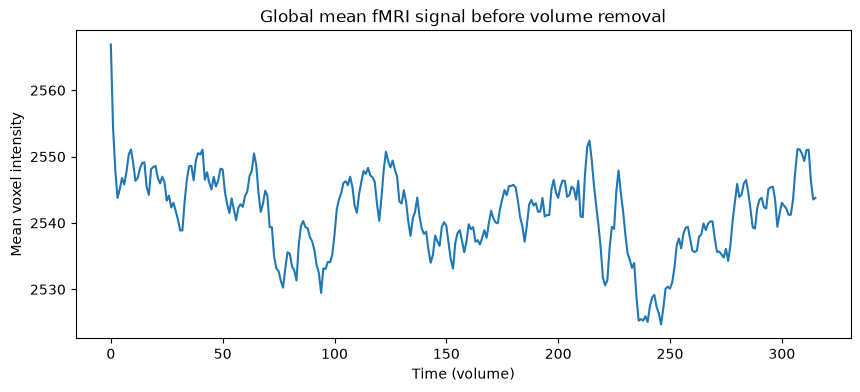

In [20]:
mean_signal = fmri_img.get_fdata().mean(axis=(0,1,2))

plt.figure(figsize=(10,4))
plt.plot(mean_signal)
plt.xlabel('Time (volume)')
plt.ylabel('Mean voxel intensity')
plt.title("Global mean fMRI signal before volume removal")
plt.show()

In [21]:
# Defining the output target
settled = op.join(func_dir, "tfMRI_LANGUAGE_LR_settled.nii.gz")


# total numeber of volumes
total_volumes = nib.load(fmri_path).shape[-1]

# from the figure we see that approximately the first volumes are the most problematic ones
# instead of removing only the first one we decide to remove the first 10 to be sure
start_vol = 10
number_of_volumes = total_volumes - start_vol 

# fslroi creates new nifti with trimmed number of volumes
if not already_done("Volume removal", settled):
    fslroi(fmri_path, settled, str(start_vol), str(total_volumes - start_vol))

# Check
assert nib.load(settled).shape[-1] == number_of_volumes, \
    "settled file has the wrong number of volumes: delete it (or set REDO = True) and rerun"

[skip] Volume removal: already done (tfMRI_LANGUAGE_LR_settled.nii.gz)


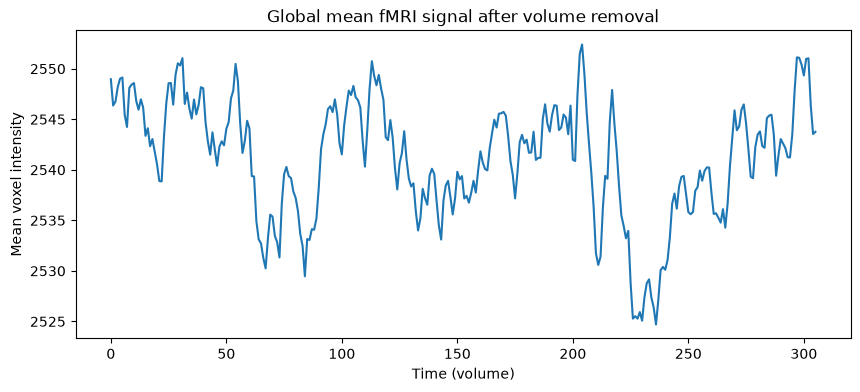

In [22]:
# Mean voxel intensity after removing the first volume
settled_img = nib.load(settled)
mean_signal_settled = settled_img.get_fdata().mean(axis=(0, 1, 2))

plt.figure(figsize=(10, 4))
plt.plot(mean_signal_settled)
plt.xlabel('Time (volume)')
plt.ylabel('Mean voxel intensity')
plt.title("Global mean fMRI signal after volume removal")
plt.show()

In [23]:
# Perform rigid-body motion correction using FSL MCFLIRT.
# MCFLIRT estimates 6 motion parameters:
# - 3 rotations (x, y, z)
# - 3 translations (x, y, z)
# Each functional volume is aligned to a reference volume to reduce spatial inconsistencies caused by head movement.


# Defining the output of the motion-corrected images
moco = op.join(func_dir, "tfMRI_LANGUAGE_LR_moco")

# motion correction
if not already_done("MCFLIRT", moco + '.nii.gz', moco + '.par'):
    mcflirt(infile=settled, o=moco, plots=True, report=True, dof=6, mats=True)
    print("Motion correction completed")

# Quality check
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(settled)
fsleyesDisplay.load(moco)

[skip] MCFLIRT: already done (tfMRI_LANGUAGE_LR_moco.nii.gz, tfMRI_LANGUAGE_LR_moco.par)


In [24]:
# Creating the .par file with motion parameters: 3 rotations (rad) + 3 translations (mm), one row per volume
mot_params = pd.read_csv(moco + '.par', sep='  ', header=None, engine='python',
                         names=['Rotation x', 'Rotation y', 'Rotation z', 'Translation x', 'Translation y', 'Translation z'])
print("Motion parameters shape:", mot_params.shape)
display(mot_params)

Motion parameters shape: (306, 6)


,Rotation x,Rotation y,Rotation z,Translation x,Translation y,Translation z
0,-0.000365,0.000062,0.000360,0.031132,0.028241,0.020636
1,-0.000300,-0.000192,-0.000084,0.035919,0.028238,-0.053232
2,-0.000374,-0.000260,-0.000279,-0.033157,0.028231,0.021839
3,-0.000436,-0.000247,-0.000084,0.032509,0.025087,0.022607
4,0.000002,-0.000136,-0.000084,-0.026343,0.028247,-0.030503
...,...,...,...,...,...,...
301,0.000262,-0.000129,-0.000307,0.046040,-0.016203,0.034743
302,0.000275,0.000385,-0.000228,0.054690,-0.013600,0.043578
303,0.000527,-0.000292,-0.000295,0.050531,-0.024428,0.041555
304,0.000105,-0.000105,-0.000315,0.046261,-0.015841,0.037342


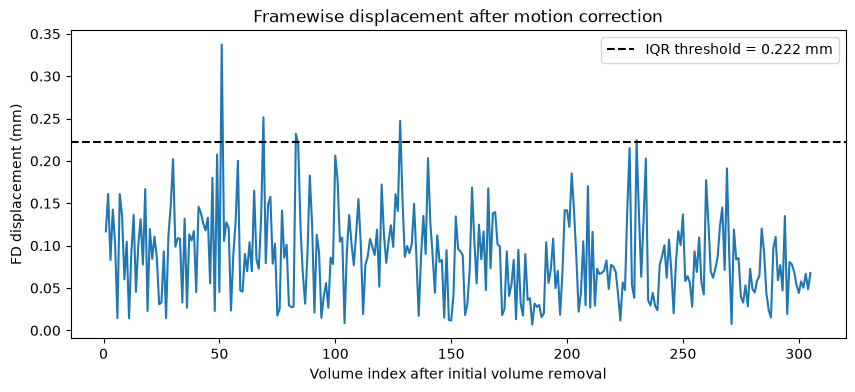

Mean FD: 0.0882 mm
Median FD: 0.0854 mm
Maximum FD: 0.3374 mm
IQR threshold: 0.2222 mm
Outlier volume indices: [51, 69, 83, 128, 230]
Outliers: 5 / 305 FD values


In [25]:
# Compute Power framewise displacement (FD).
# FD measures frame-to-frame head movement using all six motion parameters estimated by MCFLIRT.
# Rotations are converted from radians to millimetres assuming a spherical head radius of 50 mm.

# difference between consecutive volumes
framewise_diff = mot_params.diff().iloc[1:]

# rotational displacement (radiants)
rot_params = framewise_diff[['Rotation x', 'Rotation y', 'Rotation z']]

# convert rotations to equivalent displacement (mm)
converted_rots = rot_params*50

# total displacement (mm)
trans_params = framewise_diff[['Translation x', 'Translation y', 'Translation z']]

# sum of absolute rotational and translational differences
fd = converted_rots.abs().sum(axis=1) + trans_params.abs().sum(axis=1)
    


# idnetify unusually high motion 
threshold = np.quantile(fd,0.75) + 1.5*(np.quantile(fd,0.75) - np.quantile(fd,0.25))


# Data-driven outlier threshold: Q3 + 1.5 * IQR
# Identify unusually high motion:
fd_threshold = np.quantile(fd, 0.75) + 1.5*(np.quantile(fd, 0.75) - np.quantile(fd, 0.25))
# np.where(fd > fd_threshold)[0] find the indices of FD values exceeding the threshold
# FD[0] corresponds to the movement between volumes 0 and 1 of the trimmed fMRI series.
# Therefore, +1 gives the index of the later volume.
outliers  = np.where(fd > fd_threshold)[0] + 1

#%matplotlib inline
# Plot FD across the scan
plt.figure(figsize=(10, 4))
plt.plot(list(range(1, fd.size+1)), fd)
plt.xlabel('Volume index after initial volume removal')
plt.ylabel('FD displacement (mm)')
plt.title("Framewise displacement after motion correction")
plt.axhline(y=threshold,color="black",linestyle="--",label=f"IQR threshold = {threshold:.3f} mm")
plt.legend()
plt.show()

# Report summary statistics
print(f"Mean FD: {np.mean(fd):.4f} mm")
print(f"Median FD: {np.median(fd):.4f} mm")
print(f"Maximum FD: {np.max(fd):.4f} mm")
print(f"IQR threshold: {threshold:.4f} mm")

print("Outlier volume indices:", outliers.tolist())
print(f"Outliers: {len(outliers)} / {len(fd)} FD values")

### 2b Gaussian smoothing 

Gaussian spatial smoothing was applied to the motion-corrected fMRI data using FSL fslmaths, with a kernel of 6mm FWHM, corresponding to a standard deviation of approximately 2.55 mm.  

A 6 mm FWHM was selected as a compromise between improving the signal-to-noise ratio (SNR) and preserving spatial specificity; this follows the general rule that states that the FWHM should be either double or triple the voxel size of the fMRI image.   
Smoothing reduces high-frequency spatial noise by averaging neighbouring voxel intensities, but may also blur fine activation patterns.    

To assess its effect, the same functional volume (volume 100) was visualized before and after smoothing.


In [26]:
# 6 mm FWHM (about 3x the 2 mm voxel); fslmaths takes sigma = FWHM / 2.3548
smoothed = moco + "_smoothed-6mm"
fwhm = 6.0
sigma = fwhm/2.3548

if not already_done("Smoothing", smoothed + '.nii.gz'):
    subprocess.run(['fslmaths', moco, '-s', str(sigma), smoothed], check=True)
    print("Smoothing completed")

print("FWHM:", fwhm, "mm")
print("Sigma:", round(sigma, 3), "mm")

[skip] Smoothing: already done (tfMRI_LANGUAGE_LR_moco_smoothed-6mm.nii.gz)
FWHM: 6.0 mm
Sigma: 2.548 mm


In [27]:
# select one fMRI volume
vol = 100

if not already_done("Volume 100 snapshots", moco + "_vol100.nii.gz", smoothed + "_vol100.nii.gz"):
    fslroi(moco, moco + "_vol100", str(vol), str(1))
    fslroi(smoothed, smoothed + "_vol100", str(vol), str(1))

# visualize before and after smoothing
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(moco + "_vol100")
fsleyesDisplay.load(smoothed + "_vol100")

[skip] Volume 100 snapshots: already done (tfMRI_LANGUAGE_LR_moco_vol100.nii.gz, tfMRI_LANGUAGE_LR_moco_smoothed-6mm_vol100.nii.gz)


### 2c Validate the alignment between anatomical and functional data

The alignment between functional and anatomical images was visually assessed by overlaying a representative motion-corrected EPI volume onto the T1-weighted image previously normalized to MNI space using FLIRT and FNIRT.

In [28]:
# Input: motion-corrected functional data
epi_source = moco

# whole and skull-stripped structural images 
whole_t1 = t1_path
skull_stripped_t1 = op.join(anat_dir, "T1w_brain.nii.gz")

# output for EPI-to-T1 registration 
output_path = op.join(func_dir, "tfMRI_LANGUAGE_LR_moco_bbr")

# extract a representative functional volume 
ref_vol_name =  op.join(func_dir, "tfMRI_LANGUAGE_LR_moco_vol_middle")

use_single_vol = True

if use_single_vol:
    # Extract the middle volume with fslroi 
    n_volumes = nib.load(epi_source + ".nii.gz").shape[-1]
    middle_vol = n_volumes // 2
    fslroi(epi_source, ref_vol_name, str(middle_vol), str(1))
    print("Selected EPI volume:", middle_vol)

Selected EPI volume: 153


In [29]:
# Inspect EPI and MNI image geometry

epi_img = nib.load(ref_vol_name + ".nii.gz")
mni_img = nib.load(t1_mni_nonlin + ".nii.gz")

print("EPI shape:", epi_img.shape)
print("EPI voxel size:", epi_img.header.get_zooms()[:3])
print("EPI affine:")
print(epi_img.affine)

print("\nRegistered T1 shape:", mni_img.shape)
print("Registered T1 voxel size:", mni_img.header.get_zooms()[:3])
print("Registered T1 affine:")
print(mni_img.affine)

# inspect native EPI against the T1 normalized to MNI 
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(t1_mni_nonlin)
fsleyesDisplay.load(ref_vol_name)

EPI shape: (91, 109, 91)
EPI voxel size: (np.float32(2.0), np.float32(2.0), np.float32(2.0))
EPI affine:
[[  -2.    0.    0.   90.]
 [   0.    2.    0. -126.]
 [   0.    0.    2.  -72.]
 [   0.    0.    0.    1.]]

Registered T1 shape: (91, 109, 91)
Registered T1 voxel size: (np.float32(2.0), np.float32(2.0), np.float32(2.0))
Registered T1 affine:
[[  -2.    0.    0.   90.]
 [   0.    2.    0. -126.]
 [   0.    0.    2.  -72.]
 [   0.    0.    0.    1.]]


From the output above, the EPI volume and the T1 image normalized to MNI space have the same image dimensions, voxel size, and affine matrix.  

The initial overlay showed satisfactory spatial correspondence between the functional and anatomical images,
with no major misalignment of the brain boundaries or internal anatomical structures.   
This suggested that the functional data were already represented in the same standard MNI space as the anatomical image.

To further verify this observation, the same representative EPI volume was also registered to the subject’s native T1-weighted anatomical image. The resulting EPI-to-T1 affine transformation was then combined with the previously estimated nonlinear T1-to-MNI transformation from FNIRT, allowing the functional image to be transformed into MNI space.

In [30]:
# if the initial alignment is not good we register the functional EPI to the subject's anatomical T1 
# White matter partial-volume map from FAST (Part 1b)
wm_pve_path = op.join(anat_dir, "T1w_fast_pve_2.nii.gz")
white_matter_segmentation = op.join(anat_dir, "T1w_wm_mask.nii.gz") #saves it in a different file

subprocess.run([
    "fslmaths", wm_pve_path,
    "-thr", "0.5", "-bin", white_matter_segmentation
])
# register EPI to anatomical T1
subprocess.run(['epi_reg',"--epi=" + ref_vol_name, "--t1=" + whole_t1, "--t1brain=" + skull_stripped_t1, "--out=" + output_path, "--wmseg=" + white_matter_segmentation])

# EPI-to-T1 transformation matrix
epi_to_t1_mat = output_path + ".mat"

print("EPI-to-T1 matrix exists:", op.isfile(epi_to_t1_mat))

fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(skull_stripped_t1)
fsleyesDisplay.load(output_path)

FLIRT pre-alignment
Running BBR
0.936666 0.999554 -0.029581 -0.003998 0.000000 0.029306 0.997944 -0.056992 0.000000 0.005676 0.056850 0.998367 0.000000 -7.021503 -2.612739 7.600927 1.000000 
EPI-to-T1 matrix exists: True


In [31]:
# now we combine:
# EPI --> T1 (the affine matrix)
# T1 --> MNI ( the non linear transformation obtained with FNIRT)

epi_mni_path = op.join(func_dir,"tfMRI_LANGUAGE_LR_vol_MNI.nii.gz")

# MNI reference used in Part 1c with FNIRT
mni_reference = mni_2mm

# Verify the required transformations
assert op.isfile(epi_to_t1_mat), "EPI-to-T1 matrix missing"
assert op.isfile(t1_mni_warp + '.nii.gz'), "FNIRT warp missing"

# Apply combined transformation
subprocess.run(["applywarp", "--in=" + ref_vol_name,"--ref=" + mni_reference,"--warp=" + t1_mni_warp, "--premat=" + epi_to_t1_mat, "--out=" + epi_mni_path])

print("EPI successfully transformed to MNI space.")
print("Output exists:", op.isfile(epi_mni_path))

EPI successfully transformed to MNI space.
Output exists: True


In [32]:
# quality control: anatomical-functional alignment in MNI
fsleyesDisplay.resetOverlays()

# Structural T1 after FLIRT + FNIRT
fsleyesDisplay.load(t1_mni_nonlin)

# Functional EPI transformed to MNI
fsleyesDisplay.load(epi_mni_path)

Comparison of the overlay before and after this additional registration showed no substantial improvement in anatomical correspondence. The functional and structural images were already well aligned prior to the extra EPI-to-T1 and T1-to-MNI transformation.  

Therefore, the additional functional-to-anatomical registration and subsequent transformation to MNI space can be omitted in this case. Avoiding this redundant step also prevents unnecessary interpolation and resampling of the functional data.


## 3) GLM

The goal of the GLM is to investigate the activation of the brain in the math and story tasks.

a) Build an appropriate experimental design matrix that you will use in the following GLM analysis.

b) Compute and plot the correlation matrix between the regressors of the design matrix and comment on the results.

c) Run the GLM at the level you deem reasonable and report the statistical maps of each of the task-related regressors. Briefly comment on the statistical maps.

d) Using the results of the GLM analysis and a contrast vector of your choice, create the activation maps corresponding to the story vs math
contrast. Please include in the report the contrast vector used and the contrast map you obtained.

e) Discuss which brain regions and networks are more activated during numerical than semantic processing, and which are more activated in the opposite contrast. As brain activity at rest can be separated into known functional networks [2], comment the results in terms of functional networks. Report known functional networks found within the statistical results and brain activation maps. You can either observe their overlaps or use brain atlas to inform your answer.

f) [Hard] Based on the literature, some regions should stand out as particularly relevant to semantic language processing. Are these regions present in your contrast maps? If not, discuss at least two possible reasons that could explain their absence.

## Loading data
The GLM needs one time series per voxel, since the preprocessed data is already 4D:

In [33]:
from nilearn.glm.first_level import FirstLevelModel, make_first_level_design_matrix
from nilearn.glm.first_level.design_matrix import _make_drift
from nilearn.glm import threshold_stats_img
from nilearn.plotting import plot_design_matrix, plot_contrast_matrix, plot_stat_map
from nilearn.image import mean_img

# Preprocessed 4D data: volume removed, motion-corrected, smoothed
fmri_img = nib.load(smoothed + ".nii.gz")

# Number of volumes after the preprocessing:
n_scans = fmri_img.shape[-1]

# Acquisition time of each volume of the trimmed series: 0, TR, 2TR, ...
frame_times = np.arange(n_scans) * tr

Regarding the events, Nilearn needs a DataFrame with exactly three columns: onset (s), duration (s) and trial_type. Each unique trial_type becomes one regressor. 

In [34]:
# Defining the path of the events
events_path = os.path.join(data_dir, 'fMRI', 'tfMRI_LANGUAGE_LR', 'tfMRI_LANGUAGE_LR_task_onsets.csv')

# Reading and printing the events
events = pd.read_csv(events_path)
display(events)

# Since we removed "start_vol" volumes, the "t = 0" shifted, therefore 
# we need to shift all the onsets: 
events['onset'] = events['onset'] - start_vol * tr

# Keep only the task blocks: sub-events (present/question/response) are
# contained in the blocks and would create near-identical regressors
events_sm = events[events['trial_type'].isin(['story', 'math'])].copy()
display(events_sm)
events_pqr = events[events['trial_type'].isin(['present_story', 'question_story', 'response_story', 'present_math', 'question_math', 'response_math'])].copy()
display(events_pqr)

,onset,duration,trial_type
0,0.241,28.270,story
1,0.241,20.445,present_story
2,21.192,1.161,question_story
3,25.550,2.961,response_story
4,28.696,0.727,cue
5,30.095,5.667,present_math
6,30.095,12.241,math
7,35.946,3.391,question_math
8,39.371,2.965,response_math
9,42.570,5.453,present_math


,onset,duration,trial_type
0,-6.959,28.270,story
6,22.895,12.241,math
10,35.370,12.312,math
15,49.324,27.147,story
19,78.006,12.667,math
24,90.920,12.542,math
29,105.074,26.070,story
33,132.730,11.844,math
38,144.845,12.528,math
42,157.653,9.838,math


,onset,duration,trial_type
1,-6.959,20.445,present_story
2,13.992,1.161,question_story
3,18.350,2.961,response_story
5,22.895,5.667,present_math
7,28.746,3.391,question_math
8,32.171,2.965,response_math
9,35.370,5.453,present_math
11,40.981,3.702,question_math
12,44.726,2.956,response_math
14,49.324,19.821,present_story


## 3a. Building the design matrix
In order to build the GLM, first of all we need to specify EXPLAIN

We decided to add the following regressors: 
- Signal drift (slow scanner or physiological trends, modelled as low-order polynomials or cosines)
- Censoring (explain what it is)
- Motion parameters

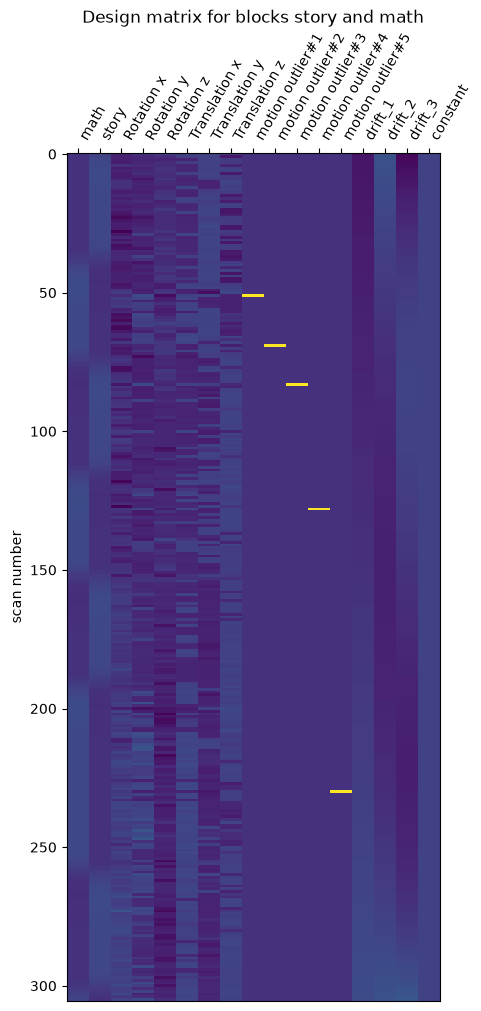

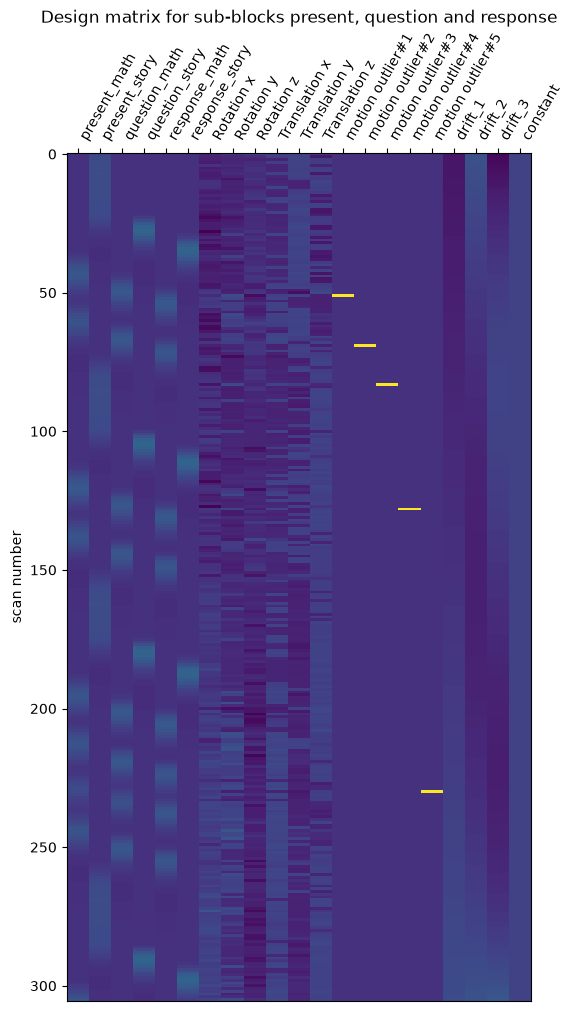

In [35]:
# Defining the regressors: 6 motion parameters from MCFLIRT
# Chek there is exacly one line per volume
assert len(mot_params) == n_scans   
# Define the confounds as the motion paramters, in order to add other regressors later on
confounds = mot_params.copy()


# Defining the regressors: censoring
# One "spike" regressor per FD outlier (1 on that volume, 0 elsewhere) is added
for i, v in enumerate(outliers):
    reg = np.zeros((n_scans,))
    reg[v] = 1.0
    confounds['motion outlier#' + str(i+1)] = reg


# Defining the design matrix keeping only the math and story block, dropping all the sub-blocks
design_mat_sm = make_first_level_design_matrix(frame_times,
                                            events_sm,
                                            hrf_model='spm',
                                            drift_model='polynomial',
                                            drift_order=3,
                                            add_regs=confounds.values,
                                            add_reg_names=list(confounds.columns))

# Defining the design matrix keeping all the sub-blocks, dropping the two math and story blocks
design_mat_pqr = make_first_level_design_matrix(frame_times,
                                            events_pqr,
                                            hrf_model='spm',
                                            drift_model='polynomial',
                                            drift_order=3,
                                            add_regs=confounds.values,
                                            add_reg_names=list(confounds.columns))

plot_design_matrix(design_mat_sm)
plt.title('Design matrix for blocks story and math')
plt.show()

plot_design_matrix(design_mat_pqr)
plt.title('Design matrix for sub-blocks present, question and response')
plt.show()

## 3b. Correlation between regressors

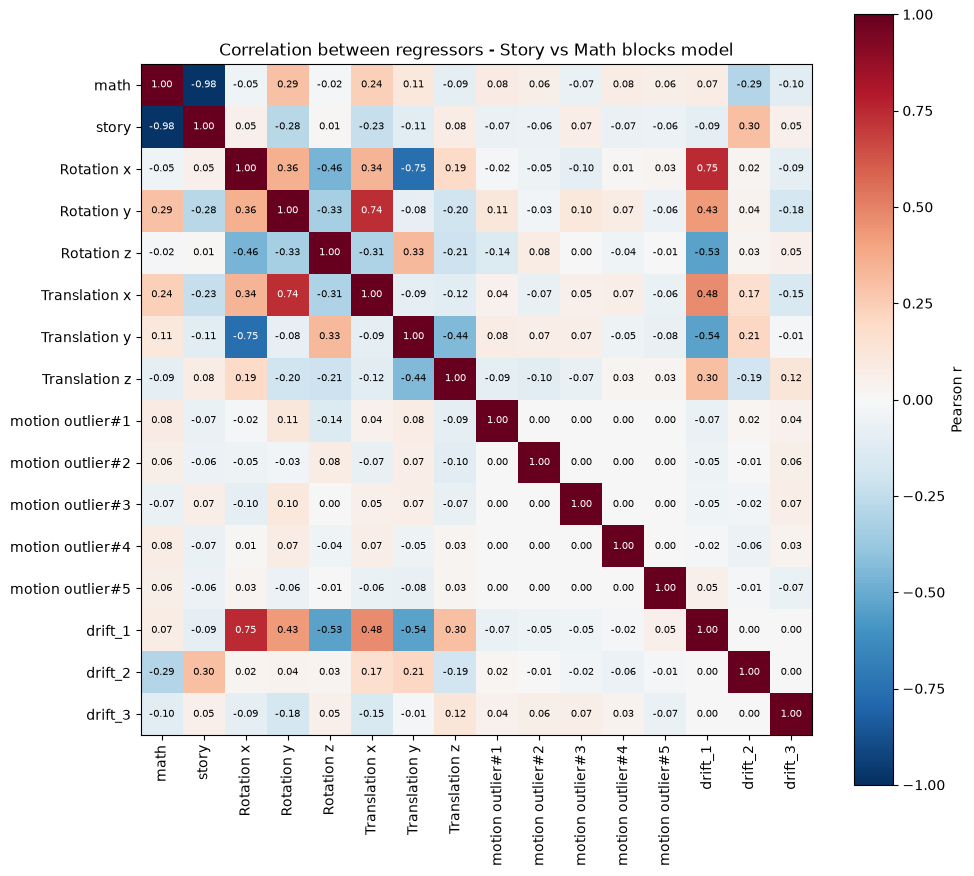

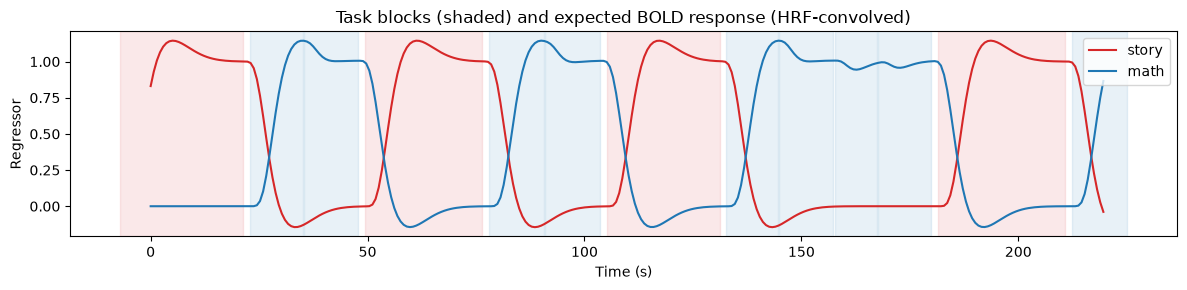

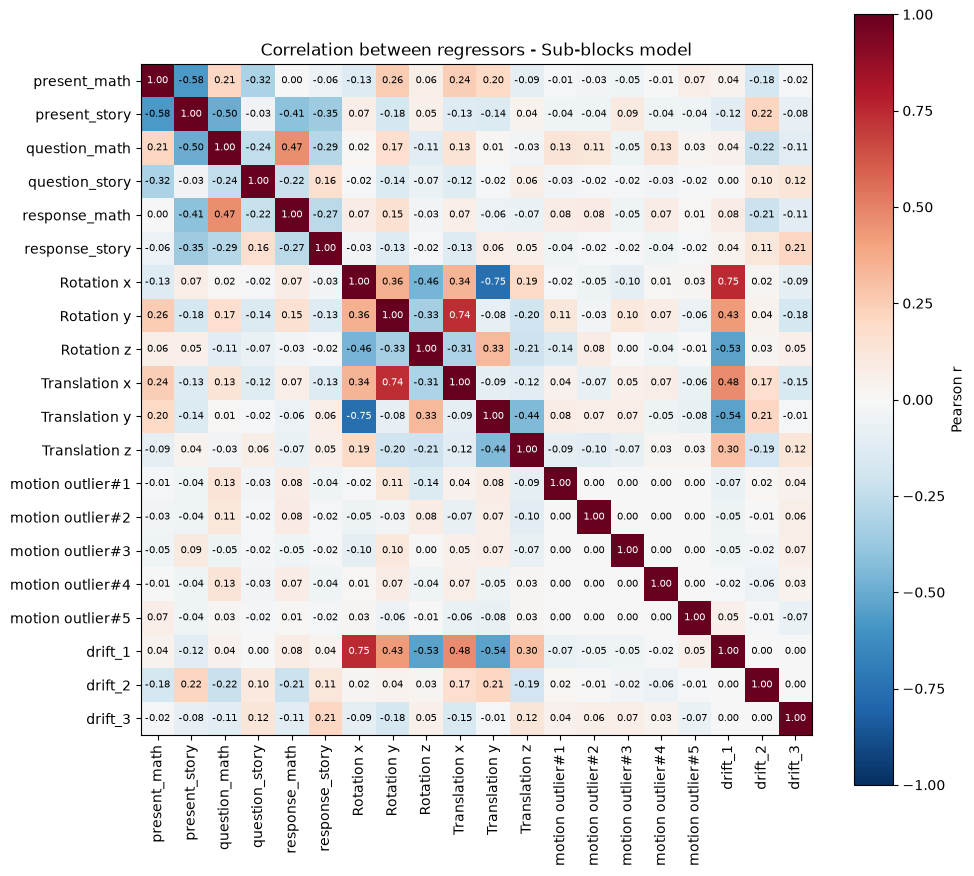

In [36]:
# Since the constant regressor has zero variance, the correlation would be NaN, therefore we do not consider it:
cols = [c for c in design_mat_sm.columns if c != 'constant'] # the two blocks model
corr = design_mat_sm[cols].corr()

# Plotting the correlation matrix for the two blocks model
fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
fig.colorbar(im, ax=ax, label='Pearson r')
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.columns)

# Write r in every cell
for i in range(len(corr)):
    for j in range(len(corr)):
        r = round(corr.iloc[i, j], 2) + 0.0       # + 0.0 turns -0.0 into 0.0
        ax.text(j, i, '{:.2f}'.format(r), ha='center', va='center', fontsize=7,
                color='white' if abs(r) > 0.6 else 'black')

ax.set_title('Correlation between regressors - Story vs Math blocks model')
plt.tight_layout()
plt.show()

# Plotting the BOLD response for the two-blocks model
fig, ax = plt.subplots(figsize=(12, 3))
for cond, color in [('story', 'tab:red'), ('math', 'tab:blue')]:
    # Shaded area = when the condition is on (the boxcar before convolution)
    for _, block in events_sm[events_sm['trial_type'] == cond].iterrows():
        ax.axvspan(block['onset'], block['onset'] + block['duration'], color=color, alpha=0.1)
    # Line = expected BOLD response (boxcar convolved with the HRF)
    ax.plot(frame_times, design_mat_sm[cond], color=color, label=cond)

ax.set(xlabel='Time (s)', ylabel='Regressor',
       title='Task blocks (shaded) and expected BOLD response (HRF-convolved)')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()



cols = [c for c in design_mat_pqr.columns if c != 'constant'] # the sub-blocks model
corr = design_mat_pqr[cols].corr()

# Plotting the correlation matrix
fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
fig.colorbar(im, ax=ax, label='Pearson r')
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.columns)

# Write r in every cell
for i in range(len(corr)):
    for j in range(len(corr)):
        r = round(corr.iloc[i, j], 2) + 0.0       # + 0.0 turns -0.0 into 0.0
        ax.text(j, i, '{:.2f}'.format(r), ha='center', va='center', fontsize=7,
                color='white' if abs(r) > 0.6 else 'black')

ax.set_title('Correlation between regressors - Sub-blocks model')
plt.tight_layout()
plt.show()

## 3c. Fitting the model
Since there is only one subject, we need to condutc a first level analysis. 

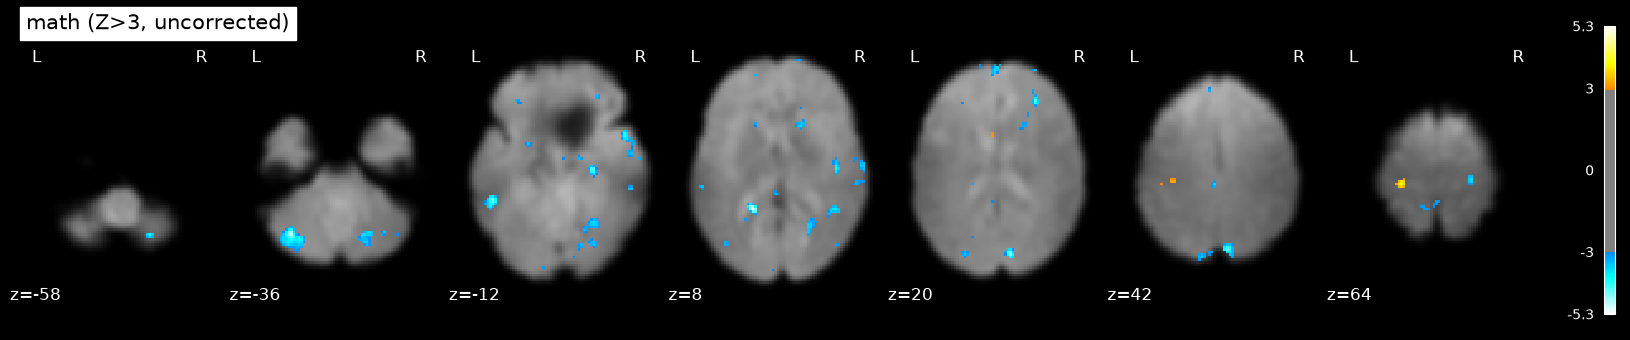

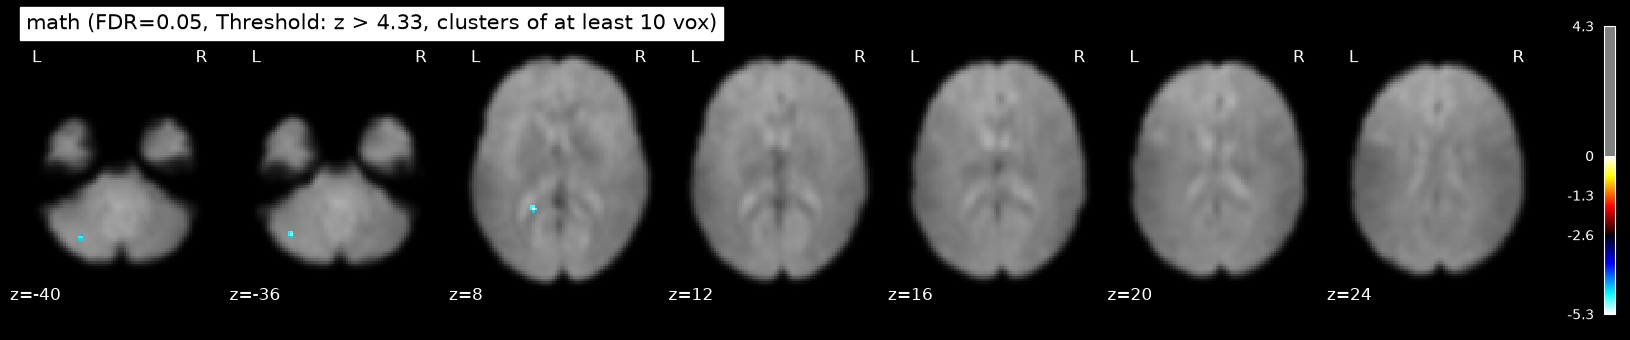

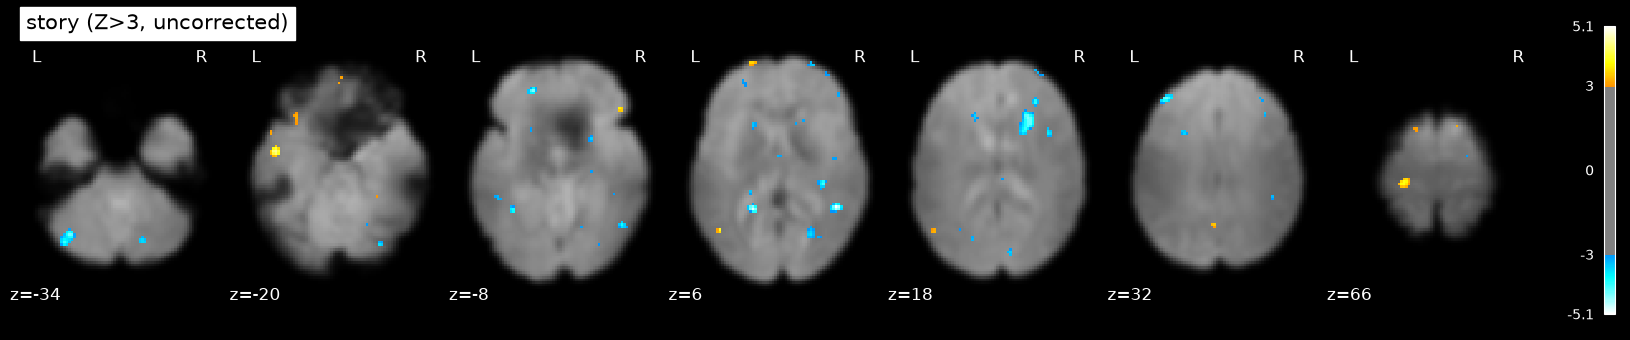

/opt/conda/lib/python3.13/site-packages/nilearn/plotting/displays/_slicers.py:308: UserWarning: empty mask
  ims = self._map_show(img, type="imshow", threshold=threshold, **kwargs)


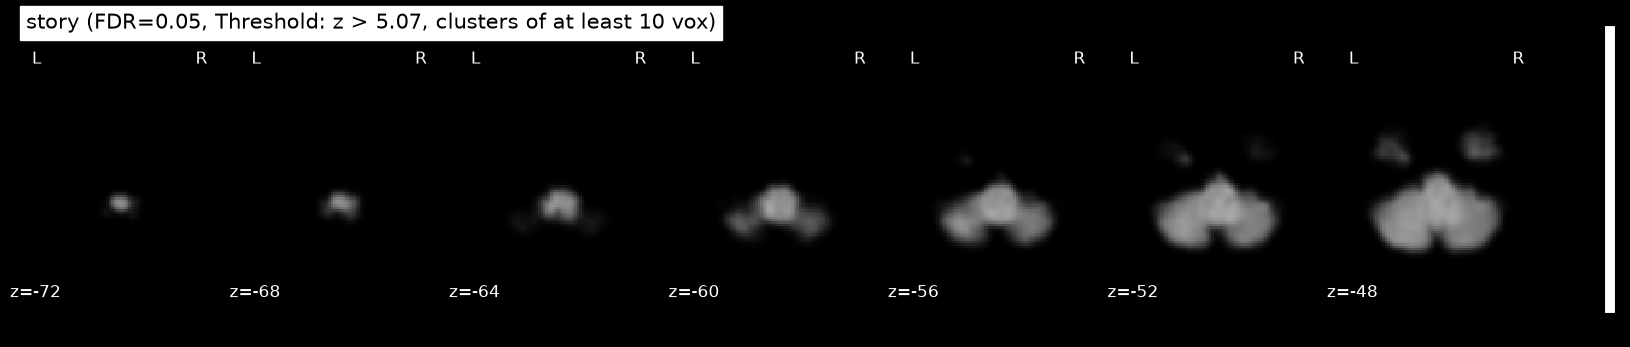

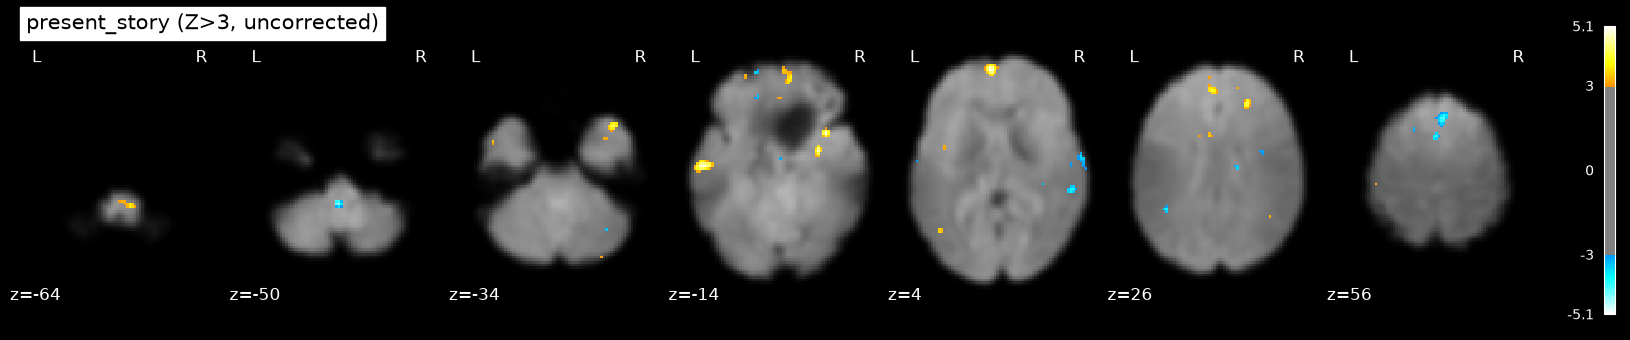

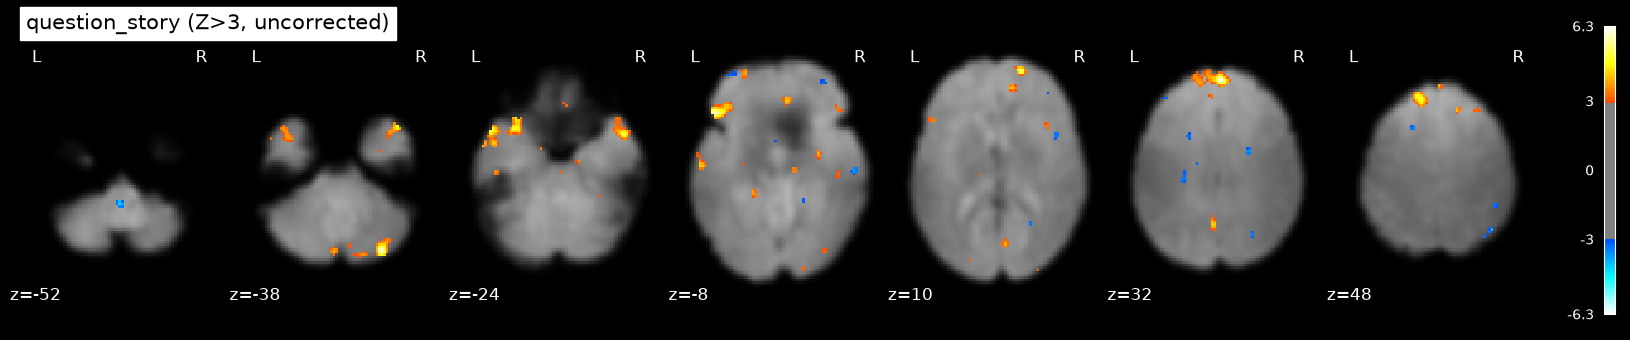

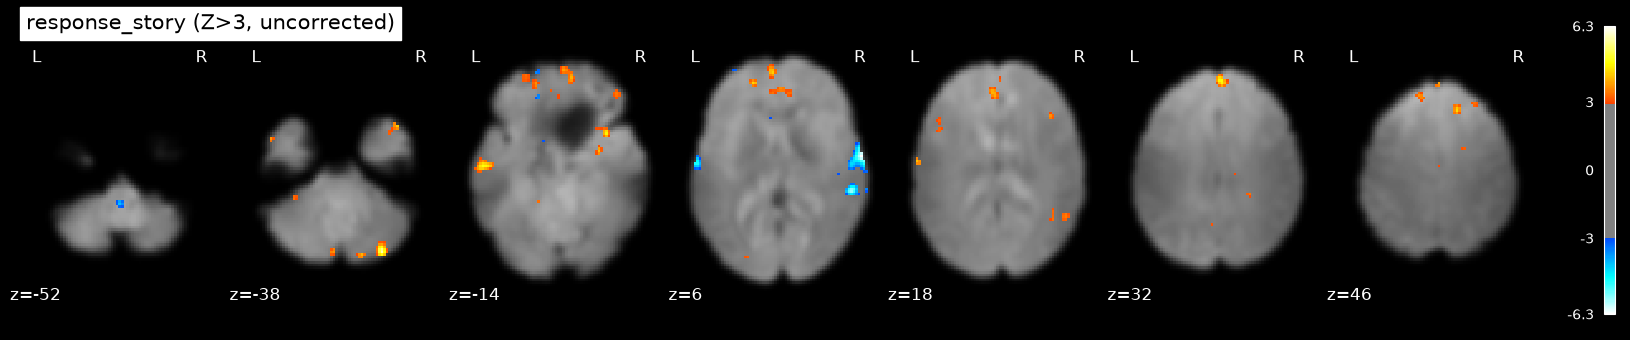

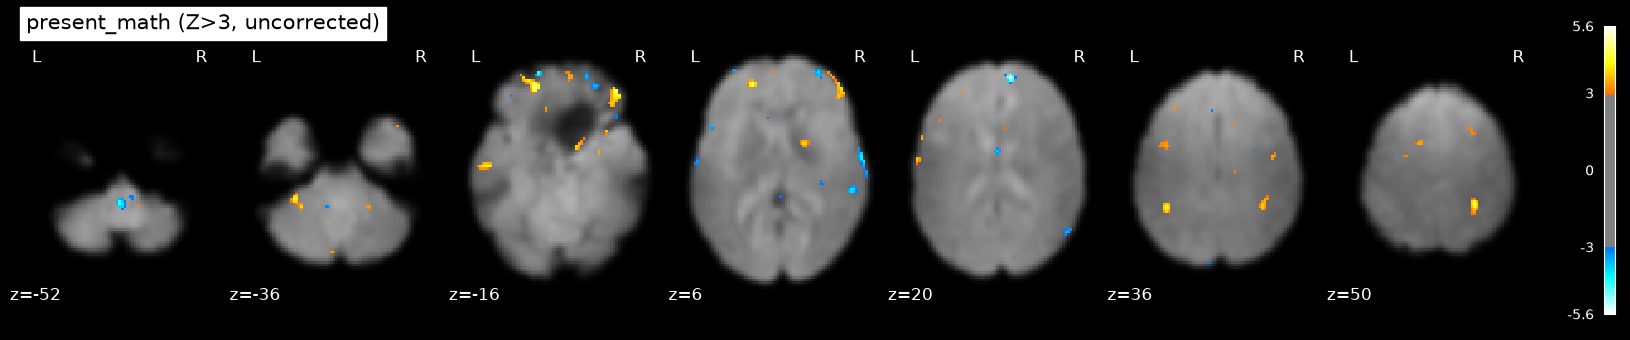

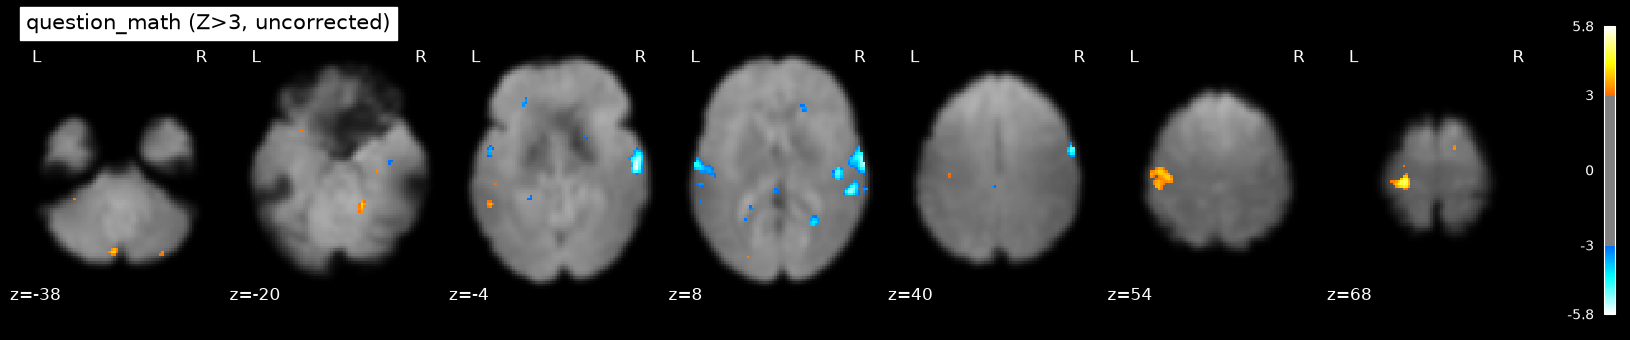

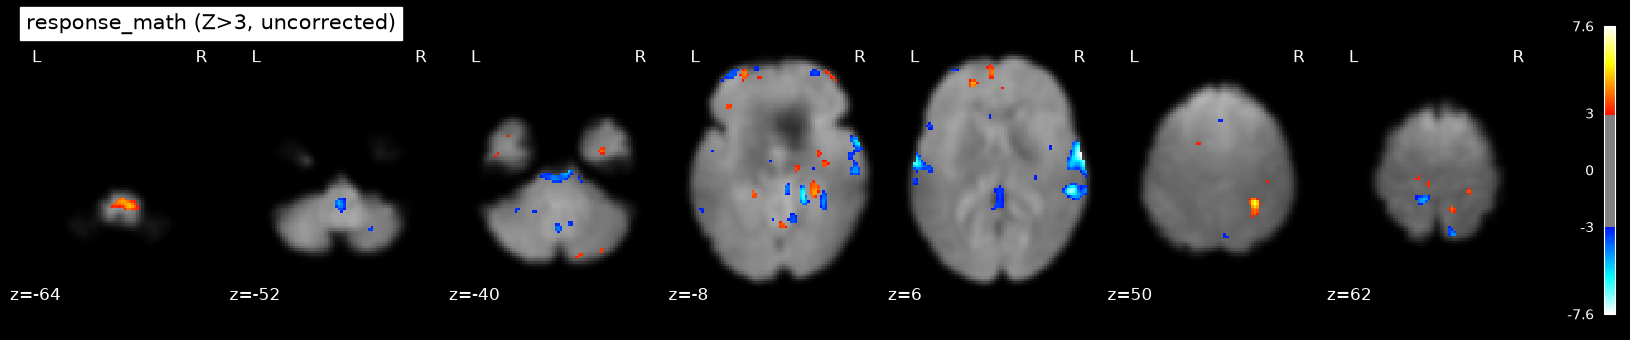

In [37]:
# First fitting for the story vs math blocks:
fit_glm_sm = FirstLevelModel(t_r=tr,
                          noise_model='ar1',
                          standardize=False)
fit_glm_sm = fit_glm_sm.fit(fmri_img, design_matrices=[design_mat_sm])

# Defining one contrast vector per condition: 1 on its column, 0 elsewhere.
# It is built from the column names so it doesn't depend on column order.
conditions_sm = {}
for cond in ['math', 'story']:
    conditions_sm[cond] = np.zeros(design_mat_sm.shape[1])
    conditions_sm[cond][design_mat_sm.columns.get_loc(cond)] = 1

# Mean functional image, used as background
mean_fmri = mean_img(fmri_img)

for cond in ['math', 'story']:
    z_map_cond = fit_glm_sm.compute_contrast(conditions_sm[cond], output_type='z_score')
    nib.save(z_map_cond, op.join(func_dir, 'z_map_{}.nii.gz'.format(cond)))
    plot_stat_map(z_map_cond, bg_img=mean_fmri, threshold=3.0,
                  display_mode='z', cut_coords=7, black_bg=True,
                  title='{} (Z>3, uncorrected)'.format(cond))
    plt.show()
    # Final plot of story and math corrected:
    cluster_size = 10
    fdr_rate = 0.05
    clean_map, threshold = threshold_stats_img(z_map_cond, alpha=fdr_rate, height_control='fdr', cluster_threshold=cluster_size)
    nib.save(clean_map, op.join(func_dir, 'z_map_{}_fdr.nii.gz'.format(cond)))

    plot_stat_map(clean_map, bg_img=mean_fmri, threshold=threshold,
                  display_mode='z', cut_coords=7, black_bg=True,
                  title='{} (FDR={}, Threshold: z > {:.2f}, clusters of at least {} vox)'.format(cond, fdr_rate, threshold, cluster_size))
    plt.show()


# Second fitting for the sub-blocks model: 
fit_glm_pqr = FirstLevelModel(t_r=tr,
                          noise_model='ar1',
                          standardize=False)
fit_glm_pqr = fit_glm_pqr.fit(fmri_img, design_matrices=[design_mat_pqr])

# Defining one contrast vector per condition: 1 on its column, 0 elsewhere.
# It is built from the column names so it doesn't depend on column order.
conditions_pqr = {}
for cond in ['present_story', 'question_story', 'response_story', 'present_math', 'question_math', 'response_math']:
    conditions_pqr[cond] = np.zeros(design_mat_pqr.shape[1])
    conditions_pqr[cond][design_mat_pqr.columns.get_loc(cond)] = 1


for cond in ['present_story', 'question_story', 'response_story', 'present_math', 'question_math', 'response_math']:
    z_map_cond = fit_glm_pqr.compute_contrast(conditions_pqr[cond], output_type='z_score')
    nib.save(z_map_cond, op.join(func_dir, 'z_map_{}.nii.gz'.format(cond)))
    plot_stat_map(z_map_cond, bg_img=mean_fmri, threshold=3.0,
                  display_mode='z', cut_coords=7, black_bg=True,
                  title='{} (Z>3, uncorrected)'.format(cond))
    plt.show()

## 3d. Contrast and activation maps "story vs math"

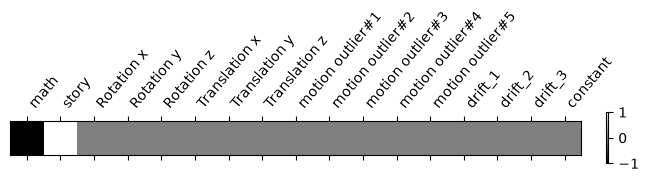

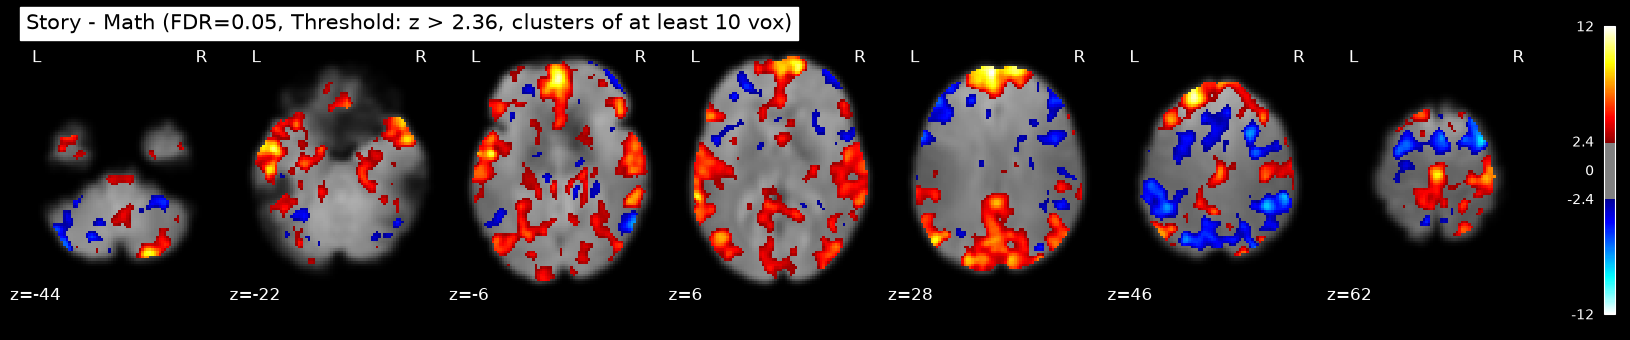

In [38]:
# For the two blocks model, the constrast is simply c = +1 on story, -1 on math, 0 elsewhere 
# This corresponds to tests beta_story - beta_math, therefore, a positive z means story > math; while 
# a negative z means math > story
story_minus_math = conditions_sm['story'] - conditions_sm['math']

plot_contrast_matrix(story_minus_math, design_matrix=design_mat_sm, colorbar=True)
plt.show()

z_map = fit_glm_sm.compute_contrast(story_minus_math, output_type='z_score')
nib.save(z_map, op.join(func_dir, 'z_map_story_minus_math.nii.gz'))

# Multiple-comparison correction: FDR 5% + clusters of at least 10 voxels
cluster_size = 10
fdr_rate = 0.05
clean_map, threshold = threshold_stats_img(z_map, alpha=fdr_rate, height_control='fdr', cluster_threshold=cluster_size)
nib.save(clean_map, op.join(func_dir, 'story_minus_math_fdr.nii.gz'))

# Plotting the activation map for "story - math"
plot_stat_map(clean_map, bg_img=mean_fmri, threshold=threshold,
              display_mode='z', cut_coords=7, black_bg=True,
              title='Story - Math (FDR={}, Threshold: z > {:.2f}, clusters of at least {} vox)'.format(fdr_rate, threshold, cluster_size))
plt.show()

fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(op.join(func_dir, 'story_minus_math_fdr.nii.gz'))

For the sub-events model we can implement different contrasts: 
1. Story - math where every sub-block is weighted by their duration
2. Story presentation - math presentation
3. Story question - math question
4. Story response - math response

story_minus_math_pqr  (sum of weights = 0.00)


Regressor,Weight
present_math,-0.46
present_story,+0.83
question_math,-0.29
question_story,+0.05
response_math,-0.25
response_story,+0.12
Rotation x,+0.00
Rotation y,+0.00
Rotation z,+0.00
Translation x,+0.00


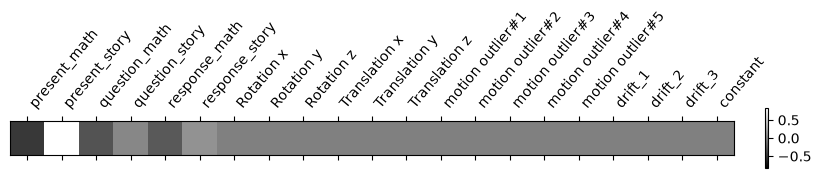

story_minus_math_pqr | z threshold: 2.41 | story>math voxels: 47431 | math>story voxels: 16580


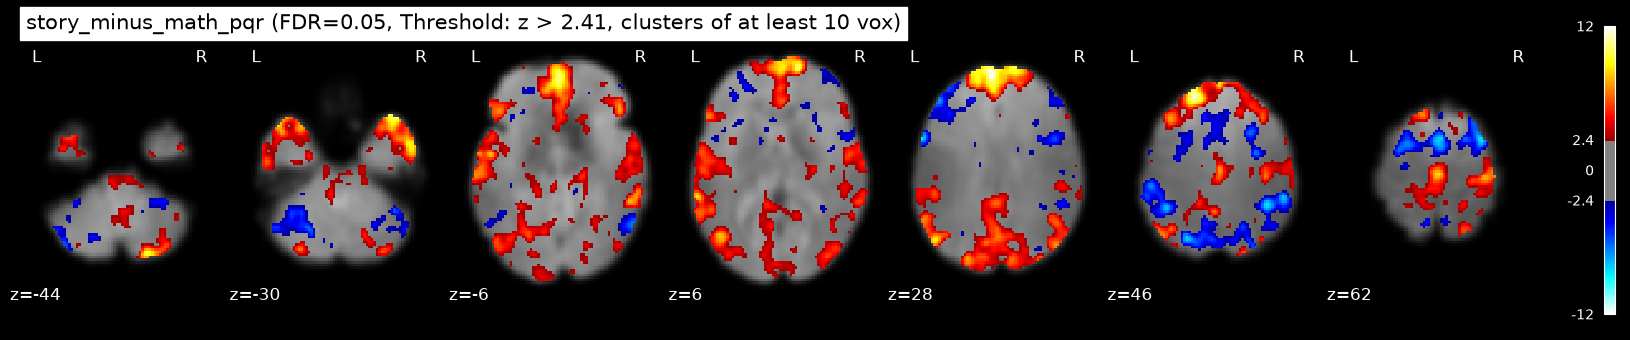

story_minus_math_pqr_equal  (sum of weights = 0.00)


Regressor,Weight
present_math,-1.00
present_story,+1.00
question_math,-1.00
question_story,+1.00
response_math,-1.00
response_story,+1.00
Rotation x,+0.00
Rotation y,+0.00
Rotation z,+0.00
Translation x,+0.00


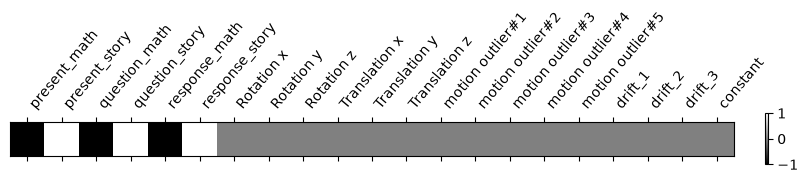

story_minus_math_pqr_equal | z threshold: 2.93 | story>math voxels: 12190 | math>story voxels: 1044


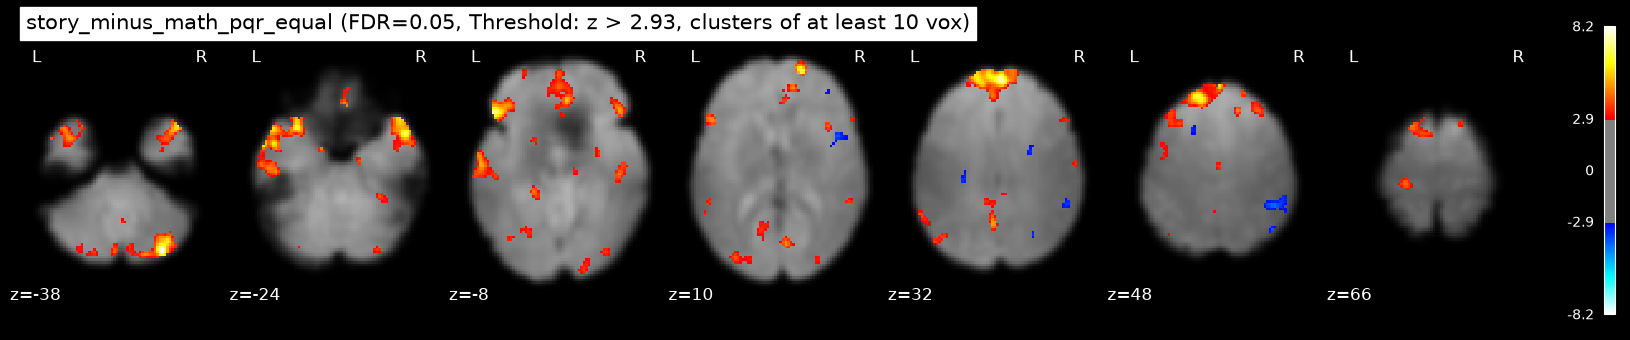

present_story_minus_present_math  (sum of weights = 0.00)


Regressor,Weight
present_math,-1.00
present_story,+1.00
question_math,+0.00
question_story,+0.00
response_math,+0.00
response_story,+0.00
Rotation x,+0.00
Rotation y,+0.00
Rotation z,+0.00
Translation x,+0.00


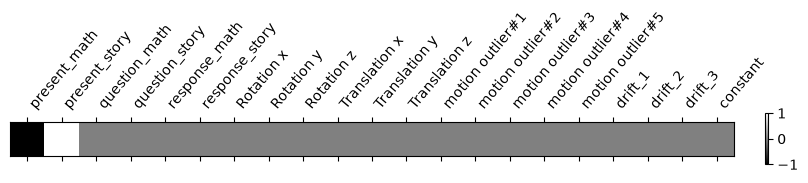

present_story_minus_present_math | z threshold: 2.43 | story>math voxels: 28896 | math>story voxels: 32044


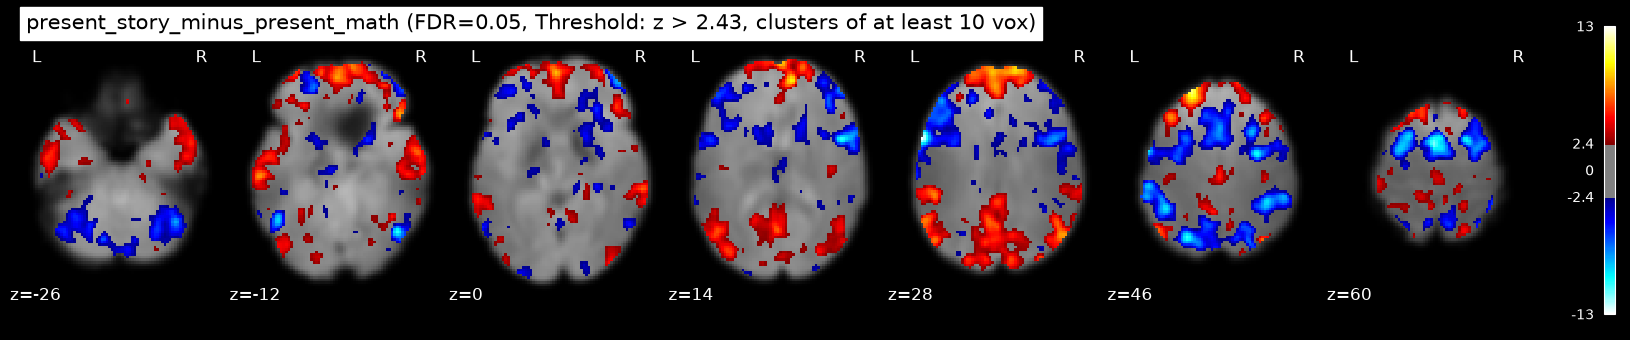

question_story_minus_question_math  (sum of weights = 0.00)


Regressor,Weight
present_math,+0.00
present_story,+0.00
question_math,-1.00
question_story,+1.00
response_math,+0.00
response_story,+0.00
Rotation x,+0.00
Rotation y,+0.00
Rotation z,+0.00
Translation x,+0.00


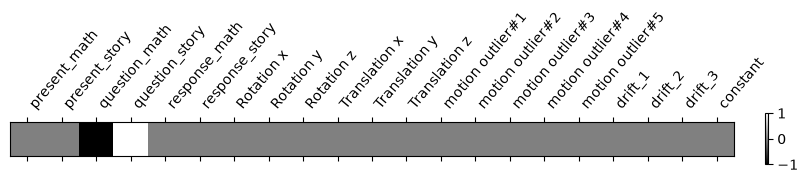

question_story_minus_question_math | z threshold: 3.17 | story>math voxels: 5112 | math>story voxels: 782


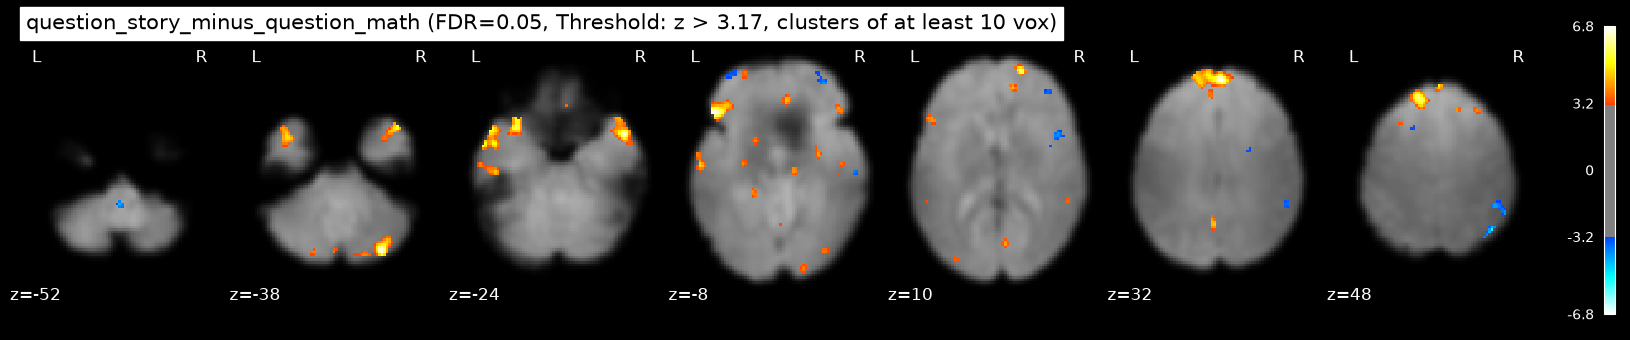

response_story_minus_response_math  (sum of weights = 0.00)


Regressor,Weight
present_math,+0.00
present_story,+0.00
question_math,+0.00
question_story,+0.00
response_math,-1.00
response_story,+1.00
Rotation x,+0.00
Rotation y,+0.00
Rotation z,+0.00
Translation x,+0.00


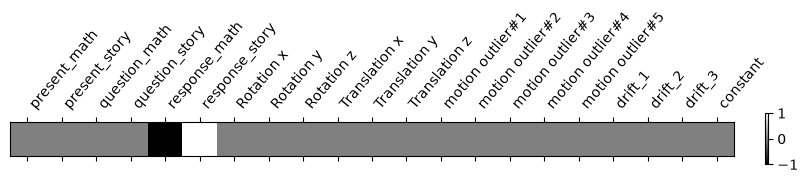

response_story_minus_response_math | z threshold: 3.10 | story>math voxels: 7369 | math>story voxels: 78


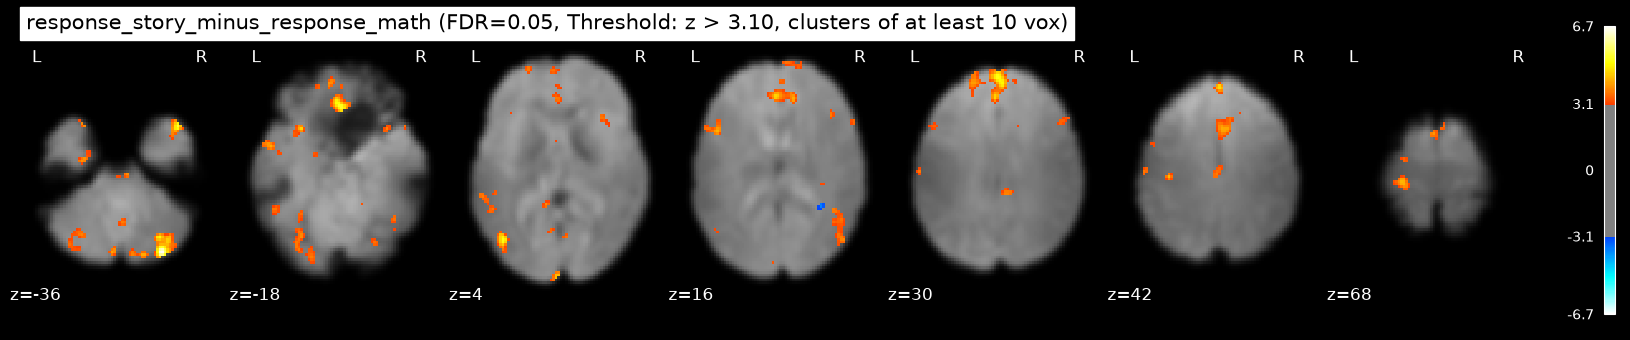

In [39]:
# Sub-event model: story - math (duration-weighted) + the three phase-by-phase differences

# Duration-weighted story - math: each phase weighted by its share of the condition's
# total time, so it asks the same question as the block model (story sums to +1, math to -1)
dur = events_pqr.groupby('trial_type')['duration'].sum()
story_phases = ['present_story', 'question_story', 'response_story']
math_phases = ['present_math', 'question_math', 'response_math']

story_minus_math_pqr = np.zeros(design_mat_pqr.shape[1])
for t in story_phases:
    story_minus_math_pqr += conditions_pqr[t] * dur[t] / dur[story_phases].sum()
for t in math_phases:
    story_minus_math_pqr -= conditions_pqr[t] * dur[t] / dur[math_phases].sum()

contrasts_pqr = {
    'story_minus_math_pqr': story_minus_math_pqr,
    'story_minus_math_pqr_equal': sum(conditions_pqr[t] for t in story_phases) - sum(conditions_pqr[t] for t in math_phases),
    'present_story_minus_present_math': conditions_pqr['present_story'] - conditions_pqr['present_math'],
    'question_story_minus_question_math': conditions_pqr['question_story'] - conditions_pqr['question_math'],
    'response_story_minus_response_math': conditions_pqr['response_story'] - conditions_pqr['response_math'],
}

z_maps_pqr = {}
for name, contrast in contrasts_pqr.items():
    # One weight per column of the model actually used
    assert len(contrast) == fit_glm_pqr.design_matrices_[0].shape[1]
    df = pd.DataFrame(
        {"Regressor": design_mat_pqr.columns,
         "Weight": [float(v) for v in contrast]}
    )
    print(f"{name}  (sum of weights = {df['Weight'].sum():.2f})")
    display(df.style.hide(axis="index").format({"Weight": "{:+.2f}"}))

    plot_contrast_matrix(contrast, design_matrix=design_mat_pqr, colorbar=True)
    plt.show()

    z_maps_pqr[name] = fit_glm_pqr.compute_contrast(contrast, output_type='z_score')
    nib.save(z_maps_pqr[name], op.join(func_dir, 'z_map_{}.nii.gz'.format(name)))

    clean_map_pqr, z_threshold_pqr = threshold_stats_img(z_maps_pqr[name], alpha=fdr_rate,
                                                         height_control='fdr',
                                                         cluster_threshold=cluster_size)
    nib.save(clean_map_pqr, op.join(func_dir, '{}_fdr.nii.gz'.format(name)))

    c = clean_map_pqr.get_fdata()
    print(name, '| z threshold: {:.2f} | story>math voxels: {} | math>story voxels: {}'.format(
        z_threshold_pqr, (c > 0).sum(), (c < 0).sum()))

    if np.isfinite(z_threshold_pqr):
        plot_stat_map(clean_map_pqr, bg_img=mean_fmri, threshold=z_threshold_pqr,
                      display_mode='z', cut_coords=7, black_bg=True,
                      title='{} (FDR={}, Threshold: z > {:.2f}, clusters of at least {} vox)'.format(name, fdr_rate, z_threshold_pqr, cluster_size))
        plt.show()
    else:
        print(name, ': no voxel survives FDR')

In [40]:
# In order to decide which regressors is better to keep, it is possible to compare the previous results
# using the block-model "story - math" as the reference:
z_ref = z_map.get_fdata()
c = clean_map.get_fdata()
print('{:36s} | story > math voxels: {} | math > story voxels: {} | peak |z|: {:.2f}'.format(
    'Block model "story - math"', (c > 0).sum(), (c < 0).sum(), np.abs(z_ref).max()))

# Spatial correlation of each sub-event map with the block map, inside the brain
for name, zm in z_maps_pqr.items():
    z = zm.get_fdata()
    inside = (z != 0) & (z_ref != 0)
    print('{:36s} | r with block story-math: {:.3f} | peak |z|: {:.2f}'.format(
        name, np.corrcoef(z[inside], z_ref[inside])[0, 1], np.abs(z).max()))

Block model "story - math"           | story > math voxels: 52378 | math > story voxels: 21027 | peak |z|: 11.83
story_minus_math_pqr                 | r with block story-math: 0.962 | peak |z|: 11.51
story_minus_math_pqr_equal           | r with block story-math: 0.572 | peak |z|: 8.21
present_story_minus_present_math     | r with block story-math: 0.844 | peak |z|: 13.13
question_story_minus_question_math   | r with block story-math: 0.393 | peak |z|: 6.84
response_story_minus_response_math   | r with block story-math: 0.344 | peak |z|: 6.73


Since the correlation between the block-model "story - math" and the sub-block model weighted by the duration have a correlation of 0.981, they are very similar. This means we can use the simpler model without loosing too much information?????

Finally, in order to verify if the cue regressor migh be "useful" for the model we can compare the two activation maps and implement and F-test

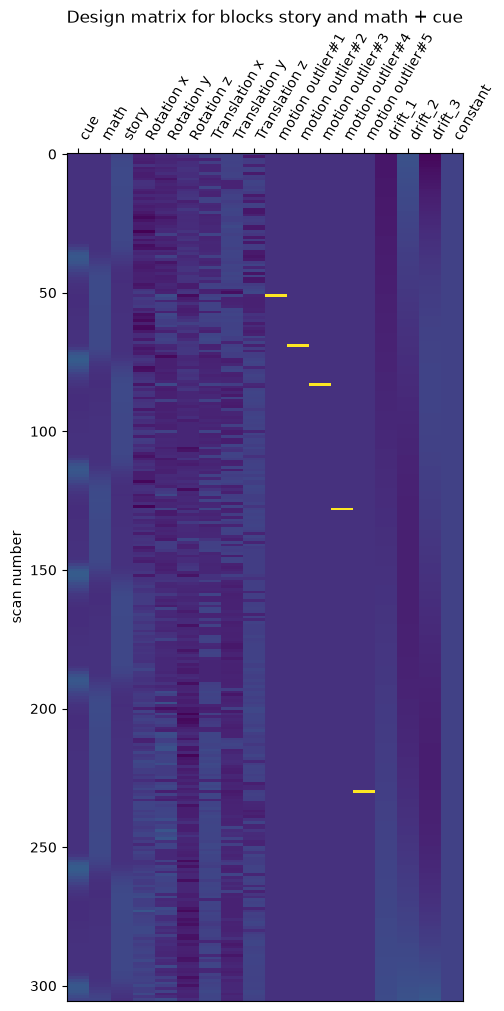

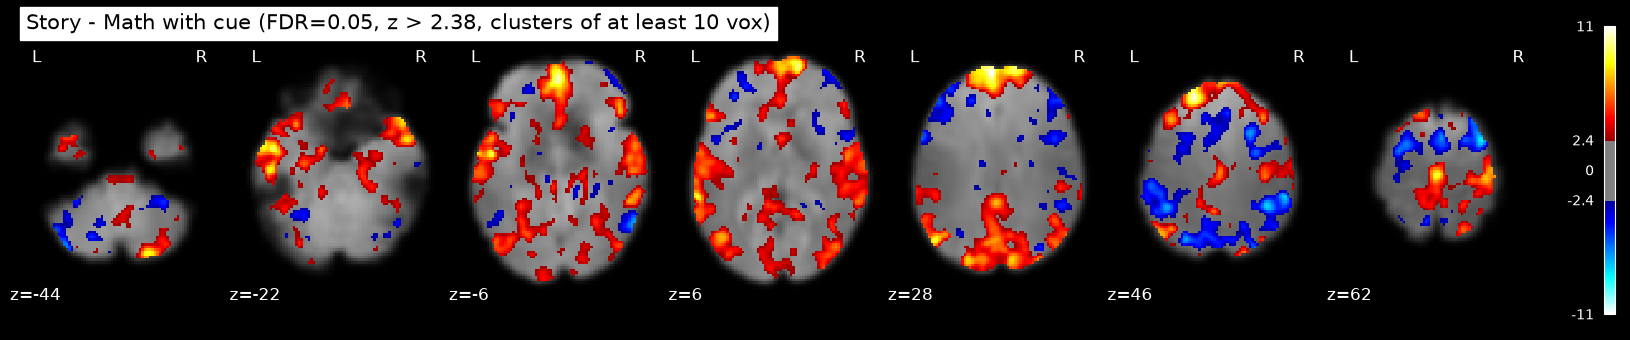

Without cue | story > math voxels: 52378 | math > story voxels: 21027 | peak |z|: 11.83
With cue    | story > math voxels: 49977 | math > story voxels: 20059 | peak |z|: 11.45
Spatial correlation of the two z-maps: r = 0.996
story > math: 93.0 % of the voxels significant without cue are still significant with cue
math > story: 91.9 % of the voxels significant without cue are still significant with cue
F-test cue | z threshold: inf | voxels where the cue improves the fit: 0 | peak z: 4.42
F-test cue: no voxel survives FDR


/opt/conda/lib/python3.13/site-packages/nilearn/glm/thresholding.py:297: UserWarning: The given float value must not exceed 4.422399491498163. But, you have given threshold=inf.
  stat_img = threshold_img(


In [41]:
# Block model + cue: same design as before, with the cue events added as a third task regressor
events_smc = events[events['trial_type'].isin(['story', 'math', 'cue'])].copy()

design_mat_smc = make_first_level_design_matrix(frame_times,
                                                events_smc,
                                                hrf_model='spm',
                                                drift_model='polynomial',
                                                drift_order=3,
                                                add_regs=confounds.values,
                                                add_reg_names=list(confounds.columns))
plot_design_matrix(design_mat_smc)
plt.title('Design matrix for blocks story and math + cue')
plt.show()

fit_glm_smc = FirstLevelModel(t_r=tr, noise_model='ar1', standardize=False)
fit_glm_smc = fit_glm_smc.fit(fmri_img, design_matrices=[design_mat_smc])

# Same contrast as before: +1 story, -1 math, 0 elsewhere (cue included)
story_minus_math_smc = np.zeros(design_mat_smc.shape[1])
story_minus_math_smc[design_mat_smc.columns.get_loc('story')] = 1
story_minus_math_smc[design_mat_smc.columns.get_loc('math')] = -1

z_map_smc = fit_glm_smc.compute_contrast(story_minus_math_smc, output_type='z_score')
nib.save(z_map_smc, op.join(func_dir, 'z_map_story_minus_math_cue.nii.gz'))

# Same multiple-comparison correction as the block model
clean_map_smc, threshold_smc = threshold_stats_img(z_map_smc, alpha=fdr_rate, height_control='fdr',
                                                   cluster_threshold=cluster_size)
plot_stat_map(clean_map_smc, bg_img=mean_fmri, threshold=threshold_smc,
              display_mode='z', cut_coords=7, black_bg=True,
              title='Story - Math with cue (FDR={}, z > {:.2f}, clusters of at least {} vox)'.format(
                  fdr_rate, threshold_smc, cluster_size))
plt.show()

# Comparison with the block model without cue
z_smc = z_map_smc.get_fdata()
c_ref = clean_map.get_fdata()
c_smc = clean_map_smc.get_fdata()
inside = (z_smc != 0) & (z_ref != 0)

print('Without cue | story > math voxels: {} | math > story voxels: {} | peak |z|: {:.2f}'.format(
    (c_ref > 0).sum(), (c_ref < 0).sum(), np.abs(z_ref).max()))
print('With cue    | story > math voxels: {} | math > story voxels: {} | peak |z|: {:.2f}'.format(
    (c_smc > 0).sum(), (c_smc < 0).sum(), np.abs(z_smc).max()))
print('Spatial correlation of the two z-maps: r = {:.3f}'.format(np.corrcoef(z_smc[inside], z_ref[inside])[0, 1]))

# Share of the significant voxels without cue that are still significant (same sign) with cue
for name, ref, new in [('story > math', c_ref > 0, c_smc > 0), ('math > story', c_ref < 0, c_smc < 0)]:
    print('{}: {:.1f} % of the voxels significant without cue are still significant with cue'.format(
        name, 100 * (ref & new).sum() / ref.sum()))

# F-test on the cue regressor: full model (story, math, cue + confounds) vs reduced model (without cue).
# H0: the cue brings no improvement in fit. With a single column, F = t^2 (two-sided t-test on beta_cue).
c_cue = np.zeros(design_mat_smc.shape[1])
c_cue[design_mat_smc.columns.get_loc('cue')] = 1

z_F_cue = fit_glm_smc.compute_contrast(c_cue, stat_type='F', output_type='z_score')
nib.save(z_F_cue, op.join(func_dir, 'z_map_F_cue.nii.gz'))

# Same correction as the other maps. two_sided=False: an F-test is one-sided (only large F is evidence),
# so negative z values must not be counted as significant
clean_F, thr_F = threshold_stats_img(z_F_cue, alpha=fdr_rate, height_control='fdr',
                                     cluster_threshold=cluster_size, two_sided=False)

n_sig = (clean_F.get_fdata() > 0).sum()
print('F-test cue | z threshold: {:.2f} | voxels where the cue improves the fit: {} | peak z: {:.2f}'.format(
    thr_F, n_sig, z_F_cue.get_fdata().max()))

if np.isfinite(thr_F) and n_sig > 0:
    plot_stat_map(clean_F, bg_img=mean_fmri, threshold=thr_F,
                  display_mode='z', cut_coords=7, black_bg=True,
                  title='F-test cue (FDR={}, z > {:.2f}, clusters of at least {} vox)'.format(
                      fdr_rate, thr_F, cluster_size))
    plt.show()
else:
    print('F-test cue: no voxel survives FDR')

## 3e. Brain regions and networks activated during numerical and semantic processing

In order to identify which brain regions and networks are more activated during numerical than semantic processing, and which are more activated in the opposite contrast, we need to use two atlases: 

- The Yeo atlas, that gives the network answer. Indeed, even when you lie in the scanner doing nothing, some brain areas rise and fall together. Yeo et all. (reference [2]) measured this in about 1000 people and found 7 networks:
    - Visual: seeing.
    - Somatomotor: moving and touch, and in this atlas also hearing.
    - Dorsal Attention: focusing on things outside you.
    - Ventral Attention: noticing what’s important.
    - Limbic: emotion and memory, at the bottom of the brain.
    - Frontoparietal: effortful thinking, the brain’s “control” system.
    - Default: thinking about meaning, stories, yourself, memories.
- The Harvard-Oxford atlas, that gives the anatomical answer.

An atlas is a brain image where every voxel carries a label instead of a measurement: “this voxel belongs to network 7” and so on. Our data is already in the same standard brain space (MNI) as the atlas, so we can just lay our activation map on top of the atlas and, for each network, count how many of our significant voxels fall inside it. More specifically, for each network we need to measure: 
1. What share of the story (or math) activation lands in this network, that tells where the activation lives.
2. What share of the network lights up, that tells how strongly the network is engaged. Otherwise, big networks would win just by being big.

In [42]:
from nilearn.image import resample_to_img
import xml.etree.ElementTree as ET

# Loading the Yeo 2011, liberal cortical mask: a local file downloaded directly from the 
# paper resources
yeo_path = op.join(data_dir, 'atlas', 'Yeo2011_7Networks_MNI152_FreeSurferConformed1mm_LiberalMask.nii')
# Unfortunately, the atlas is on a 1mm template, and our image is on a 2mm. Therefore, we have to resample the atlas
# in the right grid (the one contained in clean_map). During the resampling, each new voxel copies the label of the closest 
# old voxel, so the labels stay whole numbers 0–7. We then remove the 4th dimension that the atlas file has (using squueze)
yeo_data = np.squeeze(resample_to_img(yeo_path, clean_map, interpolation='nearest').get_fdata())
yeo_names = ['Visual', 
             'Somatomotor', 
             'Dorsal Attention', 
             'Ventral Attention', 
             'Limbic', 
             'Frontoparietal', 
             'Default']

# Loading the Harvard-Oxford cortical atlas from FSL (already on the 2 mm grid)
ho_img = nib.load(op.expandvars('$FSLDIR/data/atlases/HarvardOxford/HarvardOxford-cort-maxprob-thr25-2mm.nii.gz'))
ho_data = ho_img.get_fdata()
ho_labels = {}
for type_tag in ET.parse(op.expandvars('$FSLDIR/data/atlases/HarvardOxford-Cortical.xml')).getroot().findall('data/label'):
    ho_labels[int(type_tag.get('index')) + 1] = type_tag.text


# In order to make the analysis we need to re-use the z-map with only the 
# significant voxels, so we can take the thresholded activation map and save it in an array. 
# At the same time, it is also useful to define two true or false arrays that are 
# true where story > math is significant or viceversa, in order to use them as masks to only use 
# the values of interest from the cleaned map. 
clean = clean_map.get_fdata()
story_gt_math = clean > 0 # true where story > math is significant
math_gt_story = clean < 0 # true where math > story is significant


print('Atlas grids match the z-map:', yeo_data.shape == clean.shape == ho_data.shape)
print('Story > math voxels: {} | math > story voxels: {}'.format(story_gt_math.sum(), math_gt_story.sum()))

Atlas grids match the z-map: True
Story > math voxels: 52378 | math > story voxels: 21027


,% of network where story > math,% of network where math > story,% of significant story > math voxels that land in this newtwork,% of significant math > story voxels that land in this newtork
Network,,,,
Visual,44.2,2.1,18.8,2.2
Somatomotor,40.9,1.8,15.2,1.7
Dorsal Attention,10.4,30.3,3.0,22.0
Ventral Attention,15.8,15.9,4.1,10.3
Limbic,23.1,1.0,5.1,0.5
Frontoparietal,7.7,30.9,2.9,28.7
Default,52.8,2.6,30.4,3.7


Significant voxels outside the 7 functional networks: 20.5 % of story > math, and 30.7 % of math > story)


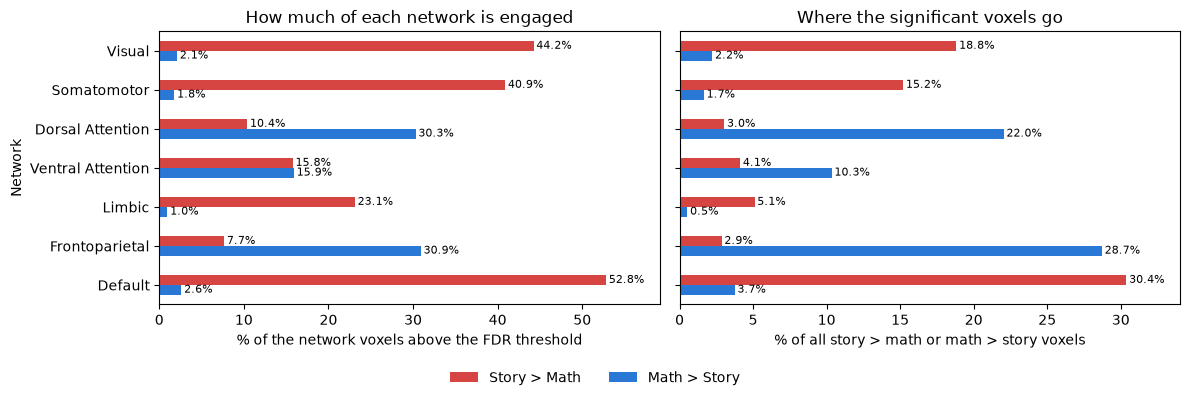

In [43]:
# In order to know which networks are involved, it is possible to count the number of significant voxels 
# in both directions (math is more active, story is more active) that are present in that specific network.
# To avoid loops on every single voxel we can define a true/false mask for each network. In this way the 
# number of true elements in the mask is the number of voxels in the network; and by checking where both the 
# conditions are true (the voxel is in the network and is significant for story > math or viceversa) we can count
# the number of voxels that fall in the network.
rows = []
for k, name in enumerate(yeo_names, start=1):
    net = yeo_data == k   # mask of network k (as make_mask_from_atlas in lab 1)
    rows.append([name,
                 100 * (net & story_gt_math).sum() / net.sum(),
                 100 * (net & math_gt_story).sum() / net.sum(),
                 100 * (net & story_gt_math).sum() / story_gt_math.sum(),
                 100 * (net & math_gt_story).sum() / math_gt_story.sum()])
networks = pd.DataFrame(rows, columns=['Network', 
                                       '% of network where story > math', 
                                       '% of network where math > story',
                                       '% of significant story > math voxels that land in this newtwork', 
                                       '% of significant math > story voxels that land in this newtork']).set_index('Network')
display(networks.round(1))
print('Significant voxels outside the 7 functional networks: {:.1f} % of story > math, and {:.1f} % of math > story)'.format(
    100 - networks['% of significant story > math voxels that land in this newtwork'].sum(), 
    100 - networks['% of significant math > story voxels that land in this newtork'].sum()))



# Plotting the percentages
# Red = story > math, blue = math > story (same colours as the positive/negative z-maps)
colors = ['#d64541', '#2a78d6']
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

networks.iloc[:, :2].plot.barh(ax=axes[0], color=colors, legend=False)
axes[0].set_title('How much of each network is engaged')
axes[0].set_xlabel('% of the network voxels above the FDR threshold')

networks.iloc[:, 2:].plot.barh(ax=axes[1], color=colors, legend=False)
axes[1].set_title('Where the significant voxels go')
axes[1].set_xlabel('% of all story > math or math > story voxels')

axes[0].invert_yaxis()   # Visual on top, same order as the table

# Write the percentage at the end of every bar
for ax in axes:
    for bars in ax.containers:
        ax.bar_label(bars, fmt='%.1f%%', padding=2, fontsize=8)
    ax.margins(x=0.12)

fig.legend(axes[0].get_legend_handles_labels()[0], ['Story > Math', 'Math > Story'],
           loc='lower center', ncol=2, frameon=False)
plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.show()

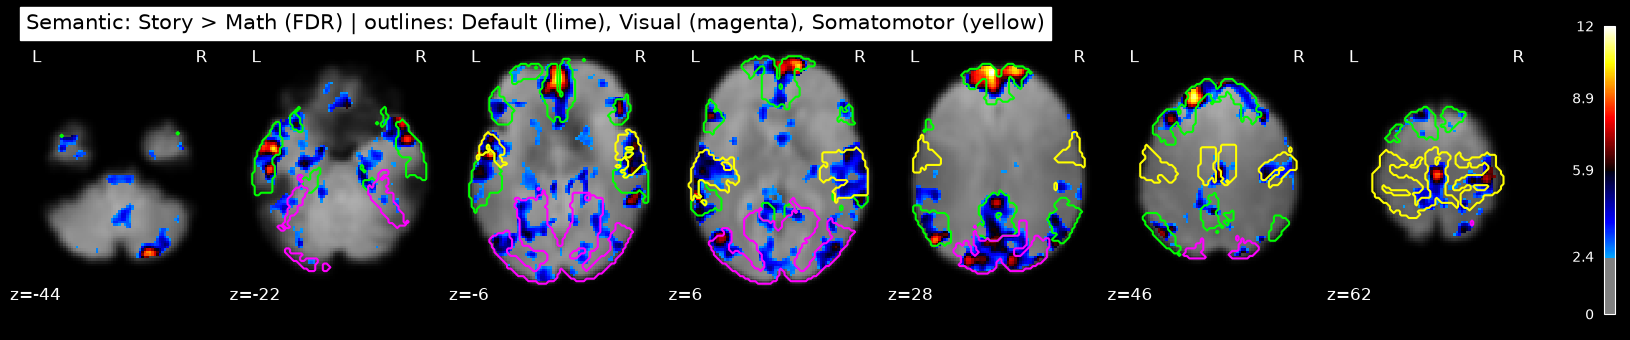

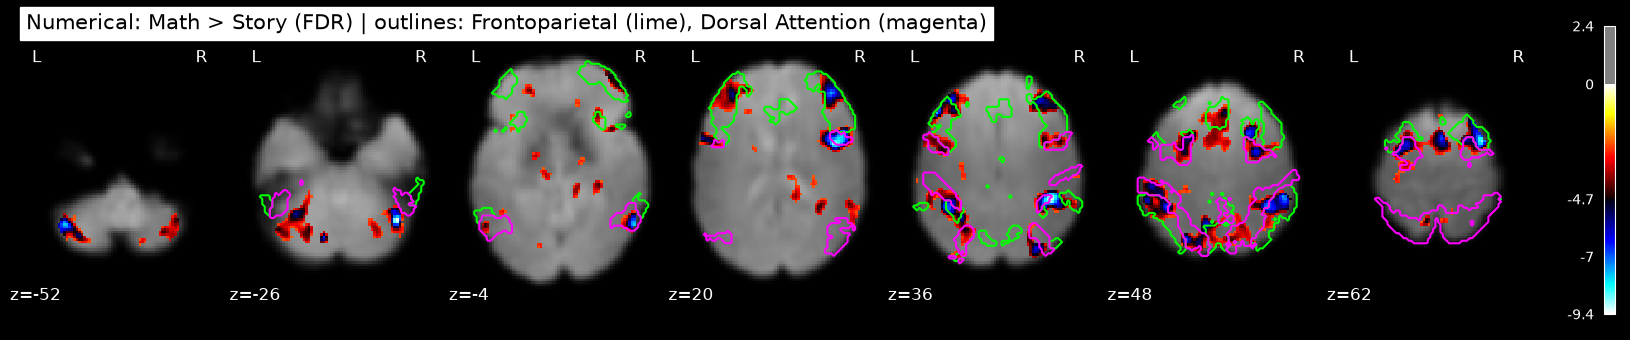

In [44]:
# Since there are five most engaged networks: story > math (red) falls mostly in Default, Visual and Somatomotor, 
# while math > story (blue) mostly in Frontoparietal and Dorsal Attention, it is possible to plot these
# three networks and overlay them witht he clean z-map to see where they are on the brain. 

# Semantic processing: story > math voxels only (positive z), with the Default and Somatomotor outlines
story_map = nib.Nifti1Image(np.where(clean > 0, clean, 0), clean_map.affine)
fig_story = plot_stat_map(story_map, bg_img=mean_fmri, threshold=threshold, display_mode='z', cut_coords=7, black_bg=True,
                          title='Semantic: Story > Math (FDR) | outlines: Default (lime), Visual (magenta), Somatomotor (yellow)')
for k, color in [(7, 'lime'), (1, 'magenta'), (2, 'yellow')]:
    fig_story.add_contours(nib.Nifti1Image((yeo_data == k).astype(np.uint8), clean_map.affine),
                           levels=[0.5], colors=color, linewidths=1.5)
plt.show()

# Numerical processing: math > story voxels only (negative z), with the Frontoparietal and Dorsal Attention outlines
math_map = nib.Nifti1Image(np.where(clean < 0, clean, 0), clean_map.affine)
fig_math = plot_stat_map(math_map, bg_img=mean_fmri, threshold=threshold, display_mode='z', cut_coords=7, black_bg=True,
                         title='Numerical: Math > Story (FDR) | outlines: Frontoparietal (lime), Dorsal Attention (magenta)')
for k, color in [(6, 'lime'), (3, 'magenta')]:
    fig_math.add_contours(nib.Nifti1Image((yeo_data == k).astype(np.uint8), clean_map.affine),
                          levels=[0.5], colors=color, linewidths=1.5)
plt.show()

# Same images in FSLeyes
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(op.join(std_dir, 'MNI152_T1_2mm'))
fsleyesDisplay.load(yeo_path)
fsleyesDisplay.setOverlayCmap(1, 'Render3')
fsleyesDisplay.load(op.join(func_dir, 'story_minus_math_fdr.nii.gz'))

In [45]:
# The same concept applies to the Harvard-Oxford atlas, to see in which anatomical regions the 
# significant voxels are located. It is also possible to see what is the functional network with 
# more voxels in that region, to have an idea of what should be the predominant functional
# network in that anatomical region. 

# In order to do so, it's necessary to distinguish when the voxel is in the right or left hemisphere. 
# This can be done defining what is our "x = 0 mm" in the template, then  x < 0 is the left hemisphere
x_mm = clean_map.affine[0, 0] * np.arange(clean.shape[0]) + clean_map.affine[0, 3]
left = (x_mm < 0)[:, None, None]

rows = []
for value, name in ho_labels.items(): # for every region (number in the Harvard-Oxford atlas and name)
    for hemi, side in [('L', left), ('R', ~left)]: # for left and right hemisphere separately
        roi = (ho_data == value) & side # mask of the region in the hemisphere

        # Count how many voxels have each each network label (0-7), dropping label 0 because it is outside of the cortex,
        # and keep the network with the most voxels (only for the networks that have at least one cortical voxel)
        region_labels = yeo_data[roi].astype(int)
        label_counts = np.bincount(region_labels, minlength=8) # how many voxels have label 0, 1, ..., 7
        network_counts = label_counts[1:]
        if network_counts.sum() > 0:
            network = yeo_names[network_counts.argmax()]
        else:
            network = '-' # no cortical voxels: no network

        rows.append([hemi + ' ' + name, network,
                     (roi & story_gt_math).sum(), 100 * (roi & story_gt_math).sum() / roi.sum(),   # story > math: # of voxels, % of region
                     (roi & math_gt_story).sum(), 100 * (roi & math_gt_story).sum() / roi.sum()])  # math > story: # of voxels, % of region

regions = pd.DataFrame(rows, columns=['Region', 'Predominant functional network', '# voxels where story > math', '% of region where story > math',
                                      '# voxels where math > story', '% of region where math > story']).set_index('Region')

# The 10 regions most engaged in each direction, ranked by % of region (so large regions do not win just by size)
print('Top 10 regions, story > math (semantic)')
display(regions.sort_values('% of region where story > math', ascending=False).head(10)[['Predominant functional network', '# voxels where story > math', '% of region where story > math']].round(1))
print('Top 10 regions, math > story (numerical)')
display(regions.sort_values('% of region where math > story', ascending=False).head(10)[['Predominant functional network', '# voxels where math > story', '% of region where math > story']].round(1))

Top 10 regions, story > math (semantic)


,Predominant functional network,# voxels where story > math,% of region where story > math
Region,,,
"L Superior Temporal Gyrus, anterior division",Default,251,99.2
L Cuneal Cortex,Visual,479,95.4
"R Superior Temporal Gyrus, anterior division",Default,253,94.4
R Cuneal Cortex,Visual,663,91.4
"L Middle Temporal Gyrus, anterior division",Default,392,87.9
"R Superior Temporal Gyrus, posterior division",Somatomotor,811,85.1
R Heschl's Gyrus (includes H1 and H2),Somatomotor,234,82.4
L Supracalcarine Cortex,Visual,59,81.9
L Occipital Fusiform Gyrus,Visual,722,78.0


Top 10 regions, math > story (numerical)


,Predominant functional network,# voxels where math > story,% of region where math > story
Region,,,
"R Inferior Frontal Gyrus, pars opercularis",Frontoparietal,316,48.2
"R Supramarginal Gyrus, posterior division",Frontoparietal,525,43.5
L Juxtapositional Lobule Cortex (formerly Supplementary Motor Cortex),Somatomotor,252,39.5
R Juxtapositional Lobule Cortex (formerly Supplementary Motor Cortex),Somatomotor,327,38.7
"L Supramarginal Gyrus, anterior division",Ventral Attention,339,35.8
R Middle Frontal Gyrus,Frontoparietal,908,35.5
L Middle Frontal Gyrus,Frontoparietal,913,33.1
R Angular Gyrus,Default,442,30.3
"L Supramarginal Gyrus, posterior division",Frontoparietal,279,26.5


## 3f. Semantic regions

,# voxels where story > math,% of region where story > math,# voxels where math > story,% of region where math > story
Region,,,,
"L Superior Temporal Gyrus, anterior division",251,99.2,0,0.0
"R Superior Temporal Gyrus, anterior division",253,94.4,0,0.0
"L Middle Temporal Gyrus, anterior division",392,87.9,0,0.0
"R Middle Temporal Gyrus, anterior division",270,67.2,0,0.0
R Frontal Medial Cortex,358,64.9,0,0.0
L Frontal Medial Cortex,254,59.9,0,0.0
L Temporal Pole,1371,58.3,0,0.0
"L Cingulate Gyrus, posterior division",584,57.6,0,0.0
R Temporal Pole,1275,54.0,0,0.0


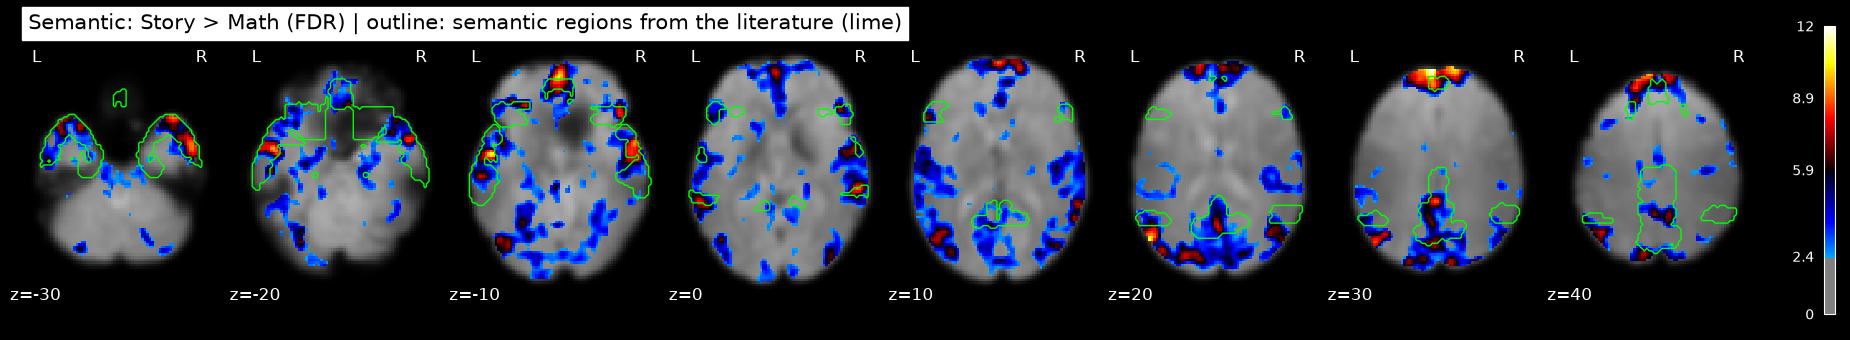

In [46]:
# Semantic regions from the literature (Binder 2009; Binder 2011 for the ATL), as Harvard-Oxford labels
semantic_rois = ['Temporal Pole', 
                 'Superior Temporal Gyrus, anterior division', 
                 'Middle Temporal Gyrus, anterior division',
                 'Middle Temporal Gyrus, posterior division', 
                 'Inferior Temporal Gyrus, anterior division',
                 'Temporal Fusiform Cortex, anterior division', 
                 'Parahippocampal Gyrus, anterior division', 
                 'Angular Gyrus',
                 'Inferior Frontal Gyrus, pars triangularis', 
                 'Frontal Orbital Cortex', 
                 'Frontal Medial Cortex',
                 'Superior Frontal Gyrus', 
                 'Cingulate Gyrus, posterior division', 
                 'Precuneous Cortex']
ho_values = {name: value for value, name in ho_labels.items()}

# We can then use the same rows as the previous cell, dropping the functional 
# network column, since is not needed here
semantic = regions.loc[[hemi + ' ' + name for name in semantic_rois for hemi in ['L', 'R']]].drop(columns='Predominant functional network')
# Show the table sorted by the share of the region that is significant for story > math
display(semantic.sort_values('% of region where story > math', ascending=False).round(1))

# Report figure: ventral slices through the ATL and orbitofrontal cortex, on the mean EPI before smoothing,
# so that the signal dropout (dark areas) is visible under the outlines
semantic_mask = np.isin(ho_data, [ho_values[name] for name in semantic_rois]).astype(np.uint8)

fig_sem = plot_stat_map(story_map, bg_img=mean_fmri, threshold=threshold, display_mode='z',
                        cut_coords=[-30, -20, -10, 0, 10, 20, 30, 40], black_bg=True,
                        title='Semantic: Story > Math (FDR) | outline: semantic regions from the literature (lime)')
fig_sem.add_contours(nib.Nifti1Image(semantic_mask, clean_map.affine), levels=[0.5], colors='lime', linewidths=1)
plt.show()

# Part 2 - PCA

Now you proceed to do a different analysis by employing multivariate pattern  analysis methods (MVPA). The goal is to find spatial maps in a data-driven manner (no GLM) and to investigate which maps would include the regions found in the GLM analysis.   

Variant 1   
1. Apply PCA on the subject fMRI runs, considering one timepoint as one sample.   
2. Select a number of components of your choice to keep while providing a  justification for your choice. Show each of the selected PCA loadings  separately, in axial view only.    
3. Compute the correlation between the (temporal) scores associated to the first 10 components and the regressors of the GLM you performed in Part 1 (including all regressors that you deem appropriate). Report the correlation matrix and comment on the results, relating them to the spatial maps obtained at point 2.



To get started, we reuse the preprocessed fMRI image, fitted designs, mean fMRI background and atlases.
The project paths stay `data_dir = op.join(parent_dir, "data")` and `output_dir = op.join(parent_dir, "outputs")`.


In [47]:
# Part 1 already provides np, pd, nib, plt, os, op, make_dir and plot_stat_map.
import json
from sklearn.decomposition import PCA

# Reuse the preprocessed run and the exact fitted block-model design. 
# Make sure everything is in the right format to move forward with the analysis. 
# We opt for a defensive programming approach, it is a little verbose, but we need to borrow a lot of work from above.
img = fmri_img
affine = img.affine
data = img.get_fdata(dtype=np.float32)
assert data.ndim == 4, 'PCA requires a 4D fMRI time series.'
vol_shape = data.shape[:3]
n_vols = data.shape[-1]
design_mat = fit_glm_sm.design_matrices_[0]
task_regressors = list(conditions_sm)
pca_expected_frame_times = np.arange(n_vols) * tr

assert np.isfinite(tr) and tr > 0, 'Invalid TR.'
assert np.isclose(img.header.get_zooms()[3], tr, rtol=0, atol=1e-5), 'Image/design TR mismatch.'
assert n_vols == len(design_mat), 'Image/design length mismatch.'
assert design_mat.index.is_unique and design_mat.columns.is_unique
assert np.allclose(design_mat.index.to_numpy(dtype=float), pca_expected_frame_times, rtol=0, atol=1e-5), 'Image/design frame-time mismatch.'
assert np.isfinite(design_mat.to_numpy(dtype=float)).all()
assert task_regressors and set(task_regressors).issubset(design_mat.columns)
assert mean_fmri.shape == vol_shape and np.allclose(mean_fmri.affine, affine)

# Inherit the project directories; all PCA derivatives live below output_dir/pca.
pca_results_dir = op.join(output_dir, 'pca')
pca_point1_results_dir = op.join(pca_results_dir, 'point_1')
make_dir(pca_point1_results_dir)
print('PCA input:', img.get_filename())
print('Retained image shape:', data.shape, '| TR:', tr, 's')
print('PCA results:', pca_results_dir)


PCA input: /data/Desktop/myfiles/NSSP_project_1/outputs/functional/tfMRI_LANGUAGE_LR_moco_smoothed-6mm.nii.gz
Retained image shape: (91, 109, 91, 306) | TR: 0.7200000286102295 s
PCA results: /data/Desktop/myfiles/NSSP_project_1/outputs/pca


## PCA - Requirement 1

Task: Apply PCA on the subject fMRI runs, considering one timepoint as one sample. 


Part 1 setup above provides the image array and fitted design. Now we need to create and inspect the first-volume foreground mask (> 500). We need to make sure that relevant tissue is retained.

Requirements 2 and 3 will reuse the same fitted model and scores.


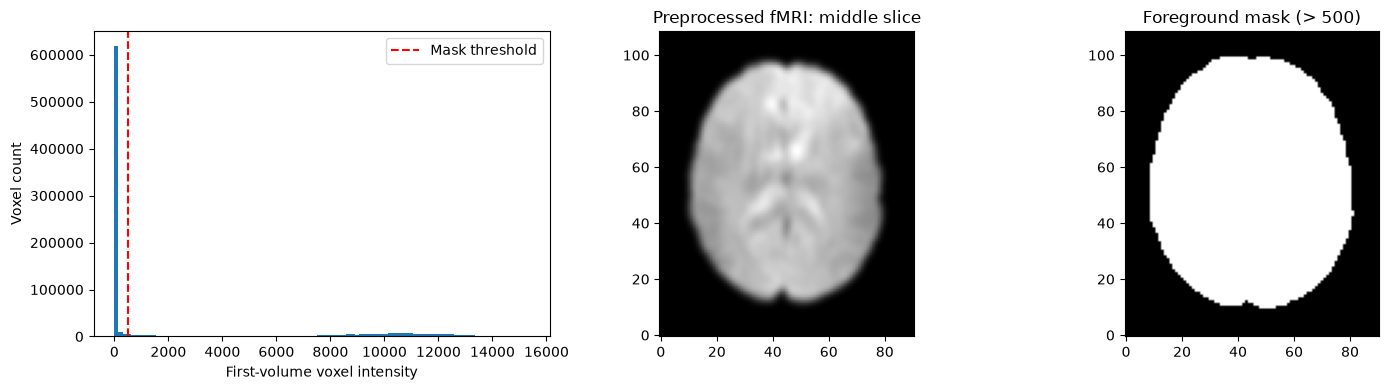

Retained timepoints x masked voxels: (306, 266603)


In [48]:
# We need, first of all, to apply a foreground mask: one fixed voxel set for all retained timepoints.
slice_non_background = data[:, :, :, 0] > 500
pca_mask_slice = vol_shape[2] // 2
pca_mask_fig, pca_mask_axes = plt.subplots(1, 3, figsize=(15, 4))
pca_mask_axes[0].hist(data[:, :, :, 0].ravel(), bins=100)
pca_mask_axes[0].axvline(500, color='red', linestyle='--', label='Mask threshold')
pca_mask_axes[0].set_xlabel('First-volume voxel intensity')
pca_mask_axes[0].set_ylabel('Voxel count')
pca_mask_axes[0].legend()
pca_mask_axes[1].imshow(data[:, :, pca_mask_slice, 0].T, cmap='gray', origin='lower')
pca_mask_axes[1].set_title('Preprocessed fMRI: middle slice')
pca_mask_axes[2].imshow(slice_non_background[:, :, pca_mask_slice].T, cmap='gray', origin='lower')
pca_mask_axes[2].set_title('Foreground mask (> 500)')
pca_mask_fig.tight_layout()
pca_mask_fig.savefig(op.join(pca_point1_results_dir, 'pca_mask_check.png'), dpi=200, bbox_inches='tight')
plt.show()
plt.close(pca_mask_fig)

# Then we can store the uncentered observations as timepoints x masked voxels.
# The centering cell below transposes this to the layout used in Lab 7.
samples = data[slice_non_background].T
print('Retained timepoints x masked voxels:', samples.shape)


### Output feedback
The mask looks already reasonable for the foreground-selection step. The histogram separates the large near-zero background peak from the higher-intensity tissue and the mask excludes the surrounding background and retains the visible brain outline.


In [49]:
# Here we reuse the masked, uncentered observations already in memory. Again, we make sure they exist and are in the expected format
assert samples.shape == (n_vols, int(slice_non_background.sum()))
assert np.isfinite(samples).all(), 'Masked fMRI contains NaN/Inf.'

# Lab 7 layout: rows are voxels, columns are retained timepoints.
# Make a float64 copy so temporal centering does not modify samples.
pca_point1_X = samples.T.astype(np.float64, copy=True)
pca_point1_temporal_means = np.mean(pca_point1_X, axis=1)
# Broadcasting is equivalent to the lab's np.outer(means, np.ones(n_vols)),
# without allocating a second full voxel-by-timepoint matrix.
pca_point1_X -= pca_point1_temporal_means[:, np.newaxis]
assert np.abs(pca_point1_X.mean(axis=-1)).max() < 1e-10

print('PCA input (timepoints x masked voxels):', pca_point1_X.T.shape)


PCA input (timepoints x masked voxels): (306, 266603)


The centering assertion passed, confirming that each voxel’s temporal mean is approximately zero. The transpose gives PCA the intended orientation: timepoints as samples, voxels as features.

Now we can fit PCA on pca_point1_X.T: **one row per timepoint (sample), one column per masked voxel (feature)**.

In [50]:
# Fit 10 as required
pca_point1_n_components = 10

pca_point1 = PCA(n_components=pca_point1_n_components, random_state=0)
pca_point1.fit(pca_point1_X.T)

print('Fitted spatial components:', pca_point1.n_components_)
print('Explained variance ratios:', pca_point1.explained_variance_ratio_)


Fitted spatial components: 10
Explained variance ratios: [0.13917096 0.0783236  0.04407797 0.03618358 0.02552004 0.02320287
 0.01996417 0.01625482 0.0143327  0.01326236]


We now know where variance originates:
- PC1 explains 13.92% of the variance.
- PC2 explains 7.83%.
- The first four together explain 29.78%.
- All ten together explain 41.03%.
The decreasing ratios are expected. We’ll assess the component cutoff using point 2’s scree plot.

In [52]:
# We will save the results before moving forward.
import pickle
pca_point1_scores = pca_point1.transform(pca_point1_X.T)

with open(op.join(pca_point1_results_dir, 'pca_model.pkl'), 'wb') as pca_point1_file:
    pickle.dump(pca_point1, pca_point1_file, protocol=pickle.HIGHEST_PROTOCOL)

np.savez_compressed(
    op.join(pca_point1_results_dir, 'pca_spatial_data.npz'),
    components=pca_point1.components_,
    mask=slice_non_background,
    affine=img.affine,
    voxel_temporal_means=pca_point1_temporal_means,
    pca_feature_mean=pca_point1.mean_,
)

pd.DataFrame(
    pca_point1_scores,
    index=design_mat.index,
    columns=[f'PC{i + 1}' for i in range(pca_point1.n_components_)],
).to_csv(op.join(pca_point1_results_dir, 'pca_scores.csv'), index_label='frame_time_s')

pd.DataFrame({
    'component': np.arange(1, pca_point1.n_components_ + 1),
    'explained_variance': pca_point1.explained_variance_,
    'explained_variance_ratio': pca_point1.explained_variance_ratio_,
    'cumulative_explained_variance_ratio': np.cumsum(pca_point1.explained_variance_ratio_),
    'singular_value': pca_point1.singular_values_,
}).to_csv(op.join(pca_point1_results_dir, 'pca_explained_variance.csv'), index=False)

pca_point1_metadata = {
    'fmri_path': op.abspath(img.get_filename()),
    'tr_s': float(tr),
    'start_vol': int(start_vol),
    'n_scans': int(n_vols),
    'spatial_shape': list(slice_non_background.shape),
    'n_masked_voxels': int(slice_non_background.sum()),
    'n_components': int(pca_point1.n_components_),
    'sample_axis': 'timepoints',
    'feature_axis': 'masked voxels',
    'centering': 'voxel temporal mean subtraction; no volume spatial mean subtraction',
    'variance_standardization': False,
    'confound_regression': False,
    'mask_definition': 'first retained volume > 500',
    'voxel_order': 'NumPy boolean indexing with the saved mask',
    'frame_time_origin': 'first_retained_volume',
    'random_state': 0,
}
with open(op.join(pca_point1_results_dir, 'metadata.json'), 'w', encoding='utf-8') as pca_point1_file:
    json.dump(pca_point1_metadata, pca_point1_file, indent=2)

print('PCA point 1 results saved to:', pca_point1_results_dir)


PCA point 1 results saved to: /data/Desktop/myfiles/NSSP_project_1/outputs/pca/point_1


## PCA - Requirement 2

Task: Select a number of components of your choice to keep while providing a
justification for your choice. Show each of the selected PCA loadings
separately, in axial view only.

We will need to inspect individual and cumulative explained variance, choose a cutoff, restore each loading vector to the spatial grid, and plot the selected maps. We will also keep the requirement 1 model intact so its first ten components remain available for requirement 3.

### Choosing the cutoff

We will use an elbow criterion. We will normalize the scree plot's component numbers and variance ratios to [0, 1], draw the line between its first and last points, and keep the components up to the point with the largest downward departure from that line.

In [55]:
pca_point2_results_dir = op.join(output_dir, 'pca', 'point_2')
make_dir(pca_point2_results_dir)

pca_point2_ratios = pca_point1.explained_variance_ratio_
pca_point2_cumulative = np.cumsum(pca_point2_ratios)
pca_point2_numbers = np.arange(1, len(pca_point2_ratios) + 1)

# Here we go about implementing Lab7 suggested elbow criterion on the fitted scree curve.
pca_point2_departures = np.zeros(len(pca_point2_ratios))
if not np.allclose(pca_point2_ratios, pca_point2_ratios[0], rtol=1e-6, atol=1e-12):
    pca_point2_x = np.linspace(0, 1, len(pca_point2_ratios))
    pca_point2_y = (pca_point2_ratios - pca_point2_ratios[-1]) / (pca_point2_ratios[0] - pca_point2_ratios[-1])
    pca_point2_departures = (1 - pca_point2_x) - pca_point2_y

if pca_point2_departures.max() > 1e-6:
    pca_point2_n_selected = int(np.argmax(pca_point2_departures)) + 1
    pca_point2_method = 'normalized scree elbow (maximum downward departure from endpoint line)'
    pca_point2_reason = (
        f'The largest downward departure from the endpoint line on the normalized scree '
        f'curve occurs at PC{pca_point2_n_selected}. We use this reproducible elbow heuristic '
        'to balance explained variance against the number of spatial maps to interpret.'
    )
else:
    pca_point2_n_selected = min(4, len(pca_point2_ratios))
    pca_point2_method = 'no elbow detected'
    pca_point2_reason = (
        'The fitted scree curve has no detectable downward bend under this criterion. '
    )
pca_point2_retained_percent = float(100 * pca_point2_cumulative[pca_point2_n_selected - 1])
pca_point2_next_percent = float(100 * pca_point2_ratios[pca_point2_n_selected])


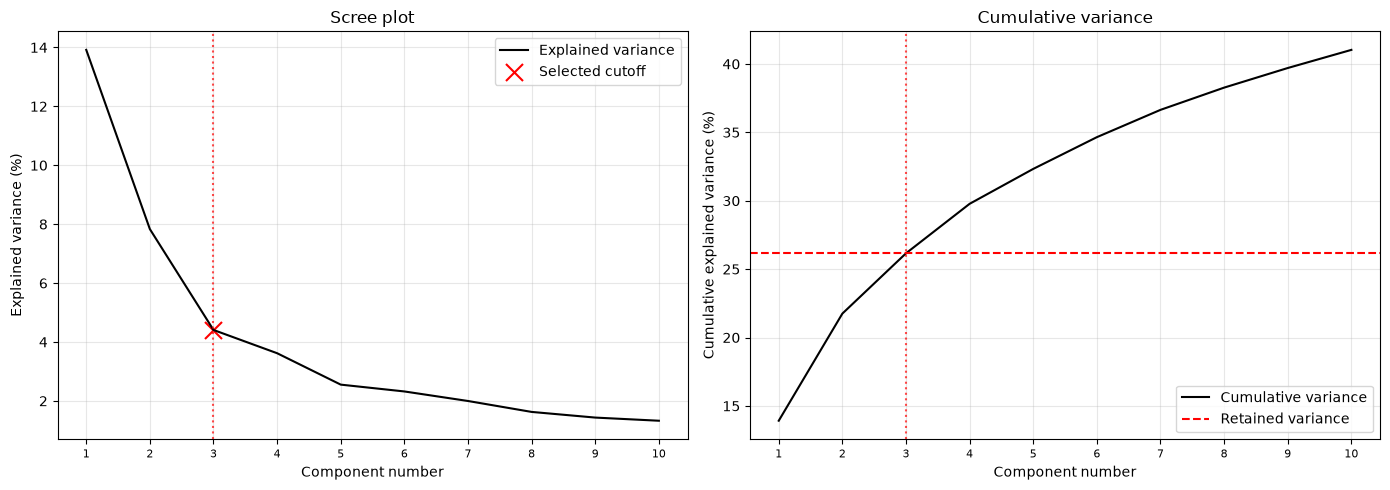

In [58]:
# Side-by-side scree and cumulative-variance plots, with the cutoff marked.
pca_point2_fig, pca_point2_axes = plt.subplots(1, 2, figsize=(14, 5))
pca_point2_axes[0].plot(pca_point2_numbers, 100 * pca_point2_ratios, c='k', label='Explained variance')
pca_point2_axes[0].scatter(
    [pca_point2_n_selected], [100 * pca_point2_ratios[pca_point2_n_selected - 1]],
    s=150, marker='x', color='r', label='Selected cutoff',
)
pca_point2_axes[0].set_ylabel('Explained variance (%)')
pca_point2_axes[0].set_title('Scree plot')
pca_point2_axes[1].plot(pca_point2_numbers, 100 * pca_point2_cumulative, c='k', label='Cumulative variance')
pca_point2_axes[1].axhline(pca_point2_retained_percent, linestyle='--', color='r', label='Retained variance')
pca_point2_axes[1].set_ylabel('Cumulative explained variance (%)')
pca_point2_axes[1].set_title('Cumulative variance')
for pca_point2_ax in pca_point2_axes:
    pca_point2_ax.axvline(pca_point2_n_selected, color='r', linestyle=':', alpha=0.7)
    pca_point2_ax.set_xlabel('Component number')
    pca_point2_ax.set_xticks(pca_point2_numbers)
    pca_point2_ax.tick_params(axis='x', labelsize=8)
    pca_point2_ax.legend()
    pca_point2_ax.grid(True, alpha=0.3)
pca_point2_fig.tight_layout()
pca_point2_fig.savefig(op.join(pca_point2_results_dir, 'pca_component_selection.png'), dpi=200, bbox_inches='tight')
plt.show()
plt.close(pca_point2_fig)


### Output feedback
Looking at the elbow, we can proceed to retain the first 3 components for spatial inspection. 
The largest downward departure from the endpoint line on the normalized scree curve occurs at PC3. We use this reproducible elbow heuristic to balance explained variance against the number of spatial maps to interpret. Together they explain 26.16% of the total temporally centered input variance; PC3 alone explains 4.41%, and the next component adds 3.62 percentage points.

### Restore the selected loadings to the image grid

We now need to create one zero-filled volume per selected component and insert its loading vector at slice_non_background. This preserves the original masked-voxel order and image affine.


In [59]:
assert pca_point1.components_.shape[1] == int(slice_non_background.sum())
assert slice_non_background.shape == img.shape[:3]
pca_point2_maps = []
for pca_point2_idx in range(pca_point2_n_selected):
    pca_point2_volume = np.zeros(slice_non_background.shape, dtype=np.float32)
    pca_point2_volume[slice_non_background] = pca_point1.components_[pca_point2_idx]
    pca_point2_maps.append(pca_point2_volume)
print('Selected spatial maps:', len(pca_point2_maps))


Selected spatial maps: 3


To satisfy requirement 2, we need to show every selected component separately, in axial view only

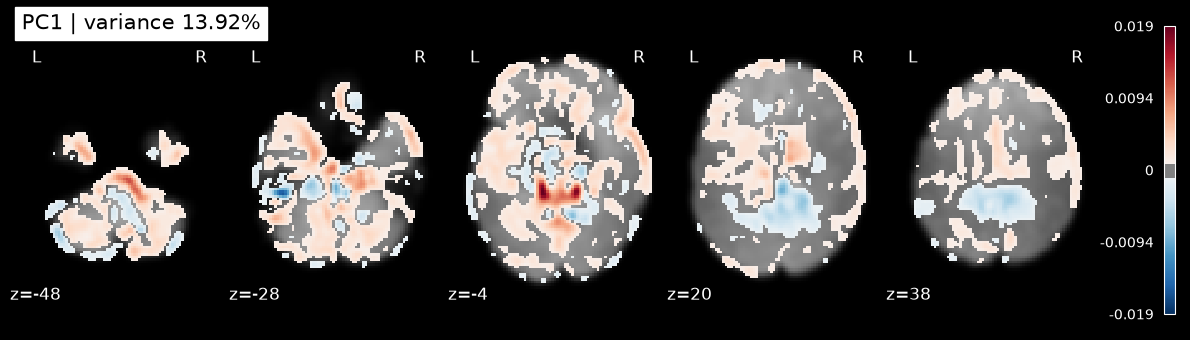

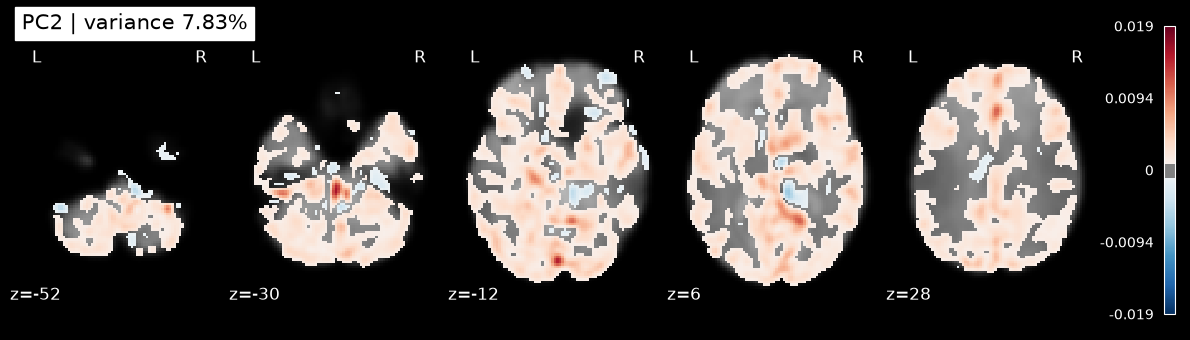

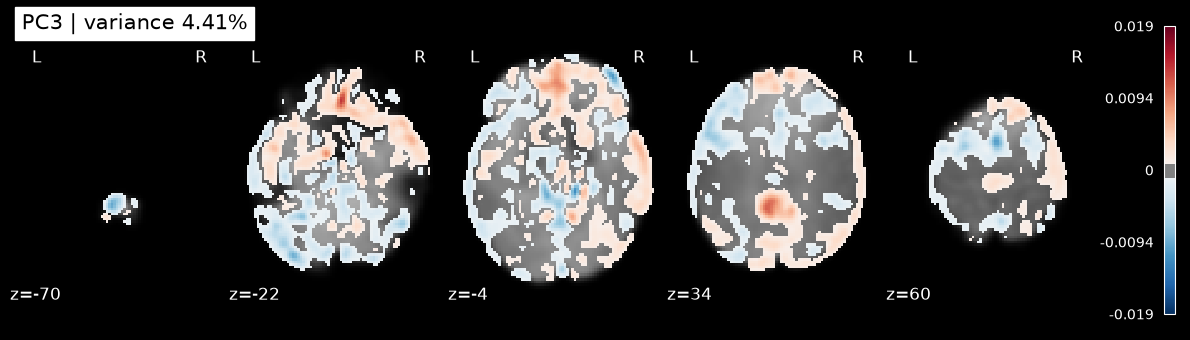

PCA point 2 results saved to: /data/Desktop/myfiles/NSSP_project_1/outputs/pca/point_2


In [60]:
assert mean_fmri.shape == img.shape[:3]
assert np.allclose(mean_fmri.affine, img.affine)
pca_point2_vmax = float(np.max(np.abs(pca_point1.components_[:pca_point2_n_selected])))
pca_point2_visual_threshold = 1e-3

for pca_point2_idx, pca_point2_volume in enumerate(pca_point2_maps):
    pca_point2_img = nib.Nifti1Image(pca_point2_volume, img.affine, img.header.copy())
    pca_point2_img.set_data_dtype(np.float32)
    pca_point2_stem = f'PC{pca_point2_idx + 1:02d}'
    pca_point2_img.to_filename(op.join(pca_point2_results_dir, pca_point2_stem + '_loadings.nii.gz'))

    pca_point2_display = plot_stat_map(
        pca_point2_img, bg_img=mean_fmri,
        display_mode='z', cut_coords=5,
        threshold=pca_point2_visual_threshold,
        cmap='RdBu_r', symmetric_cbar=True, vmax=pca_point2_vmax,
        black_bg=True,
        title=f'PC{pca_point2_idx + 1} | variance {100 * pca_point2_ratios[pca_point2_idx]:.2f}%',
    )
    # Keep the small threshold labels from overlapping around zero.
    pca_point2_display._cbar.set_ticks(np.linspace(-pca_point2_vmax, pca_point2_vmax, 5))
    pca_point2_display.savefig(op.join(pca_point2_results_dir, pca_point2_stem + '_axial.png'), dpi=200)
    plt.show()
    pca_point2_display.close()

print('PCA point 2 results saved to:', pca_point2_results_dir)


### Output feedback

From these displayed slices:
- PC1 (13.92%) shows widespread positive weights with some prominent negative regions.
- PC2 (7.83%) appears predominantly positive and spatially widespread.
- PC3 (4.41%) shows a more mixed pattern of positive and negative weights.

One detail: the automatic slice selection chose different axial coordinates for each component. That still satisfies the requirement.

# PCA - Requirement 3

Task: Compute the correlation between the (temporal) scores associated to the first
10 components and the regressors of the GLM you performed in Part 1
(including all regressors that you deem appropriate). Report the correlation
matrix and comment on the results, relating them to the spatial maps obtained
at point 2.


Firstly, we need to do some alignment checks.

In [61]:
pca_point3_results_dir = op.join(output_dir, 'pca', 'point_3')
make_dir(pca_point3_results_dir)
pca_point3_designs = {
    'blocks': fit_glm_sm.design_matrices_[0],
    'subevents': fit_glm_pqr.design_matrices_[0],
}
pca_point3_task_names = {
    'blocks': list(conditions_sm),
    'subevents': list(conditions_pqr),
}

# The PCA image must be the same preprocessed run used by the Part 1 GLMs. We need to check everything is in place.
assert img.shape == fmri_img.shape
assert np.allclose(img.affine, fmri_img.affine)
assert op.realpath(img.get_filename()) == op.realpath(fmri_img.get_filename()), 'PCA and GLM must use the same input run.'
assert pca_point1_scores.shape == (n_vols, 10)
assert pca_point1.n_components_ == 10
assert np.isfinite(pca_point1_scores).all()
assert (pca_point1_scores.std(axis=0) > 1e-12).all(), 'A score has zero variance; Pearson r is undefined.'

pca_point3_columns = [f'PC{i + 1}' for i in range(10)]
pca_point3_frame_times = design_mat.index.to_numpy(dtype=float)
assert len(pca_point3_frame_times) == n_vols
assert np.allclose(pca_point3_frame_times, np.arange(n_vols) * tr, rtol=0, atol=1e-5)
pca_point3_score_df = pd.DataFrame(pca_point1_scores[:, :10], index=design_mat.index.copy(), columns=pca_point3_columns)
pca_point3_score_df.index.name = 'frame_time_s'

for pca_point3_name, pca_point3_design in pca_point3_designs.items():
    assert len(pca_point3_design) == n_vols
    assert pca_point3_design.index.is_unique and pca_point3_design.columns.is_unique
    assert np.allclose(pca_point3_design.index.to_numpy(dtype=float), pca_point3_frame_times, rtol=0, atol=1e-5), 'GLM/PCA frame-time mismatch.'
    assert np.isfinite(pca_point3_design.to_numpy(dtype=float)).all()
    assert set(pca_point3_task_names[pca_point3_name]).issubset(pca_point3_design.columns)
print('Aligned observations:', n_vols, '| PCA scores:', len(pca_point3_columns))


Aligned observations: 306 | PCA scores: 10


Alignment is valid. Now we can finally compute the correlation matrices!


blocks | excluded constants: ['constant']


,math,story,Rotation x,Rotation y,Rotation z,Translation x,Translation y,Translation z,motion outlier#1,motion outlier#2,motion outlier#3,motion outlier#4,motion outlier#5,drift_1,drift_2,drift_3
PC1,-0.162,0.163,-0.656,-0.398,0.320,-0.456,0.486,-0.119,0.061,-0.013,0.042,0.036,-0.090,-0.815,0.056,0.170
PC2,-0.386,0.362,0.325,-0.011,-0.354,0.095,-0.200,0.260,-0.025,-0.075,-0.133,-0.031,-0.124,0.340,0.368,0.002
PC3,-0.648,0.649,0.010,-0.517,0.070,-0.554,-0.254,0.221,-0.078,0.022,0.022,-0.044,0.003,-0.135,-0.143,0.122
PC4,-0.277,0.308,-0.171,0.100,0.194,0.142,0.351,-0.354,-0.033,0.051,0.010,-0.061,0.044,-0.144,0.393,-0.340
PC5,-0.016,0.017,-0.233,-0.176,0.276,-0.072,0.271,-0.266,-0.141,0.007,-0.042,-0.041,-0.030,-0.210,0.259,-0.136
PC6,0.324,-0.336,-0.080,-0.154,0.077,-0.232,-0.051,0.160,-0.001,0.089,-0.097,0.004,0.048,-0.114,-0.310,-0.074
PC7,0.169,-0.166,-0.220,-0.144,0.048,-0.131,0.276,-0.070,0.013,0.064,-0.049,-0.015,-0.004,-0.146,0.105,-0.064
PC8,-0.002,-0.024,-0.019,0.183,-0.133,0.190,0.134,-0.165,-0.005,-0.070,0.075,-0.064,-0.073,0.036,0.045,-0.084
PC9,0.111,-0.112,-0.082,-0.153,0.087,-0.210,0.017,0.082,0.043,-0.049,-0.056,0.001,0.072,-0.040,-0.096,0.037
PC10,0.025,-0.035,-0.025,-0.282,0.018,-0.333,0.038,0.263,-0.126,-0.065,-0.101,-0.044,0.102,0.179,0.066,-0.047


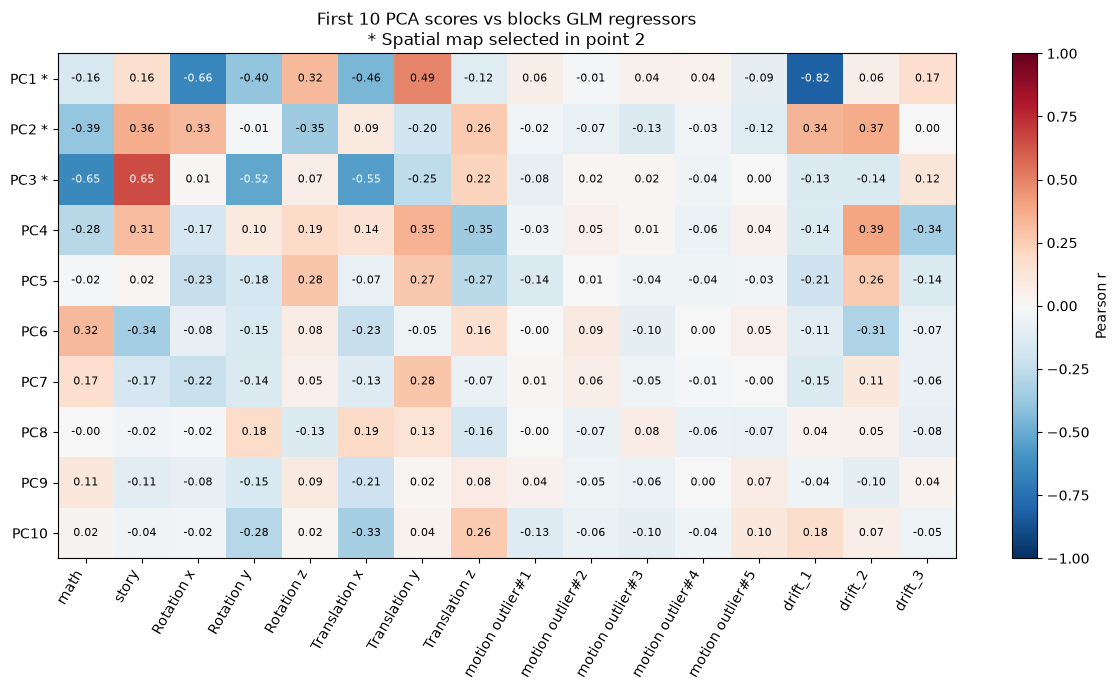

subevents | excluded constants: ['constant']


,present_math,present_story,question_math,question_story,response_math,response_story,Rotation x,Rotation y,Rotation z,Translation x,Translation y,Translation z,motion outlier#1,motion outlier#2,motion outlier#3,motion outlier#4,motion outlier#5,drift_1,drift_2,drift_3
PC1,-0.020,0.066,-0.135,0.108,-0.239,0.153,-0.656,-0.398,0.320,-0.456,0.486,-0.119,0.061,-0.013,0.042,0.036,-0.090,-0.815,0.056,0.170
PC2,-0.193,0.111,-0.288,0.282,-0.366,0.355,0.325,-0.011,-0.354,0.095,-0.200,0.260,-0.025,-0.075,-0.133,-0.031,-0.124,0.340,0.368,0.002
PC3,-0.678,0.565,-0.344,0.253,-0.186,0.010,0.010,-0.517,0.070,-0.554,-0.254,0.221,-0.078,0.022,0.022,-0.044,0.003,-0.135,-0.143,0.122
PC4,-0.224,0.267,-0.097,0.163,-0.257,-0.062,-0.171,0.100,0.194,0.142,0.351,-0.354,-0.033,0.051,0.010,-0.061,0.044,-0.144,0.393,-0.340
PC5,0.181,-0.019,-0.239,0.016,-0.063,0.098,-0.233,-0.176,0.276,-0.072,0.271,-0.266,-0.141,0.007,-0.042,-0.041,-0.030,-0.210,0.259,-0.136
PC6,0.266,-0.247,0.334,-0.202,0.018,-0.033,-0.080,-0.154,0.077,-0.232,-0.051,0.160,-0.001,0.089,-0.097,0.004,0.048,-0.114,-0.310,-0.074
PC7,0.116,-0.197,0.082,0.011,0.161,0.014,-0.220,-0.144,0.048,-0.131,0.276,-0.070,0.013,0.064,-0.049,-0.015,-0.004,-0.146,0.105,-0.064
PC8,0.052,0.091,-0.050,-0.166,-0.035,-0.087,-0.019,0.183,-0.133,0.190,0.134,-0.165,-0.005,-0.070,0.075,-0.064,-0.073,0.036,0.045,-0.084
PC9,0.098,-0.125,0.120,-0.053,-0.008,0.011,-0.082,-0.153,0.087,-0.210,0.017,0.082,0.043,-0.049,-0.056,0.001,0.072,-0.040,-0.096,0.037
PC10,0.116,-0.184,-0.024,0.213,-0.102,0.146,-0.025,-0.282,0.018,-0.333,0.038,0.263,-0.126,-0.065,-0.101,-0.044,0.102,0.179,0.066,-0.047


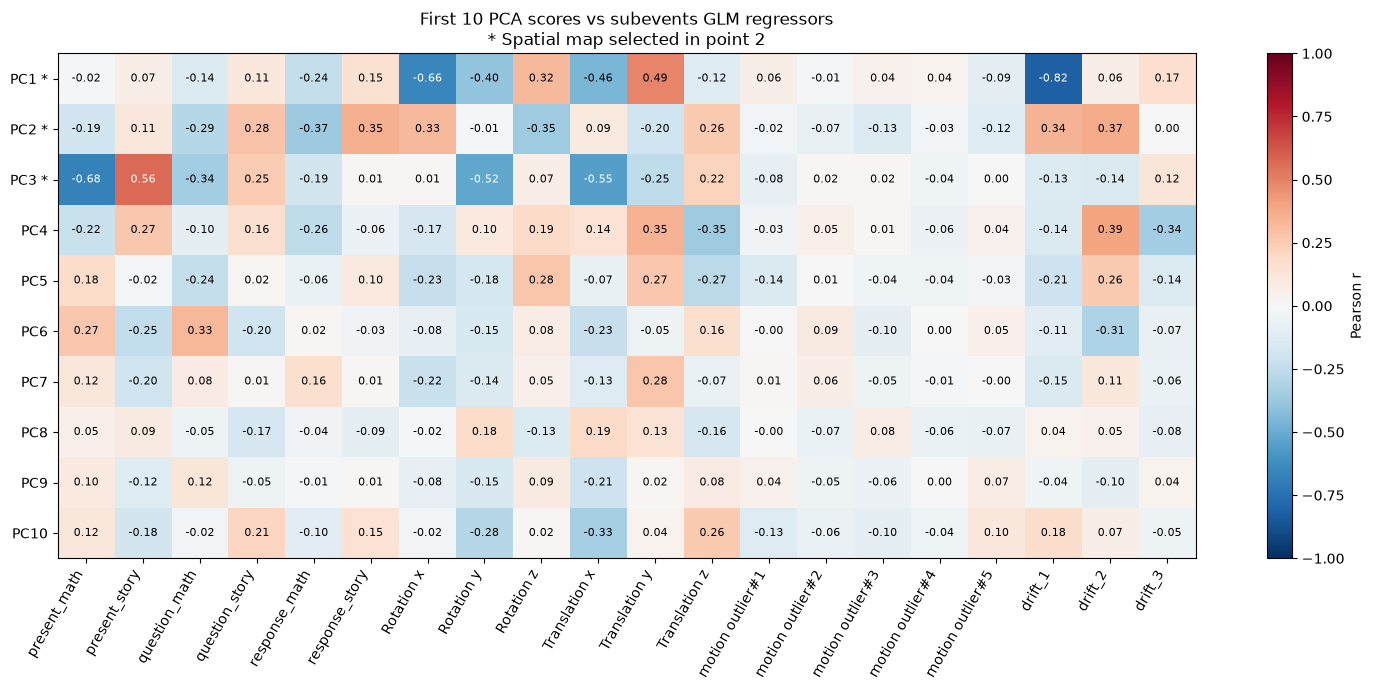

,model,PC,explained_variance_percent,map_selected,strongest_task,task_r,strongest_nuisance,nuisance_r
0,blocks,PC1,13.917,True,story,0.163,drift_1,-0.815
1,blocks,PC2,7.832,True,math,-0.386,drift_2,0.368
2,blocks,PC3,4.408,True,story,0.649,Translation x,-0.554
3,blocks,PC4,3.618,False,story,0.308,drift_2,0.393
4,blocks,PC5,2.552,False,story,0.017,Rotation z,0.276
5,blocks,PC6,2.320,False,story,-0.336,drift_2,-0.310
6,blocks,PC7,1.996,False,math,0.169,Translation y,0.276
7,blocks,PC8,1.625,False,story,-0.024,Translation x,0.190
8,blocks,PC9,1.433,False,story,-0.112,Translation x,-0.210
9,blocks,PC10,1.326,False,story,-0.035,Translation x,-0.333


In [62]:
pca_point3_correlations = {}
pca_point3_excluded = {}
pca_point3_summary_rows = []
for pca_point3_name, pca_point3_design in pca_point3_designs.items():
    pca_point3_regressors = [c for c in pca_point3_design.columns if pca_point3_design[c].std(ddof=0) > 1e-12]
    pca_point3_excluded[pca_point3_name] = [c for c in pca_point3_design.columns if c not in pca_point3_regressors]
    pca_point3_tasks = [c for c in pca_point3_task_names[pca_point3_name] if c in pca_point3_regressors]
    pca_point3_nuisance = [c for c in pca_point3_regressors if c not in pca_point3_tasks]
    assert pca_point3_tasks, 'No variable task regressors remain.'
    pca_point3_corr = pd.DataFrame(index=pca_point3_columns, columns=pca_point3_regressors, dtype=float)
    for pca_point3_pc in pca_point3_columns:
        for pca_point3_regressor in pca_point3_regressors:
            # Use the already-checked row order, avoiding accidental pandas index realignment.
            pca_point3_corr.loc[pca_point3_pc, pca_point3_regressor] = np.corrcoef(
                pca_point3_score_df[pca_point3_pc].to_numpy(),
                pca_point3_design[pca_point3_regressor].to_numpy(),
            )[0, 1]
    assert np.isfinite(pca_point3_corr.to_numpy()).all()
    assert (np.abs(pca_point3_corr.to_numpy()) <= 1 + 1e-12).all()
    pca_point3_correlations[pca_point3_name] = pca_point3_corr
    pca_point3_corr.to_csv(op.join(pca_point3_results_dir, pca_point3_name + '_correlations.csv'), index_label='PC')
    pca_point3_design[pca_point3_regressors].to_csv(
        op.join(pca_point3_results_dir, pca_point3_name + '_regressors.csv'), index_label='frame_time_s')
    print(pca_point3_name, '| excluded constants:', pca_point3_excluded[pca_point3_name])
    display(pca_point3_corr.round(3))

    pca_point3_fig, pca_point3_ax = plt.subplots(figsize=(max(12, 0.75 * len(pca_point3_regressors)), 7))
    pca_point3_heatmap = pca_point3_ax.imshow(pca_point3_corr, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
    pca_point3_fig.colorbar(pca_point3_heatmap, ax=pca_point3_ax, label='Pearson r')
    pca_point3_ax.set_xticks(np.arange(len(pca_point3_regressors)), labels=pca_point3_regressors, rotation=60, ha='right')
    pca_point3_ax.set_yticks(np.arange(10), labels=[pc + (' *' if i < pca_point2_n_selected else '') for i, pc in enumerate(pca_point3_columns)])
    for pca_point3_i in range(10):
        for pca_point3_j in range(len(pca_point3_regressors)):
            pca_point3_r = pca_point3_corr.iloc[pca_point3_i, pca_point3_j]
            pca_point3_ax.text(pca_point3_j, pca_point3_i, f'{pca_point3_r:.2f}', ha='center', va='center',
                               color='white' if abs(pca_point3_r) > 0.5 else 'black', fontsize=8)
    pca_point3_ax.set_title(f'First 10 PCA scores vs {pca_point3_name} GLM regressors\n* Spatial map selected in point 2')
    pca_point3_fig.tight_layout()
    pca_point3_fig.savefig(op.join(pca_point3_results_dir, pca_point3_name + '_correlations.png'), dpi=200, bbox_inches='tight')
    plt.show()
    plt.close(pca_point3_fig)

    for pca_point3_i, pca_point3_pc in enumerate(pca_point3_columns):
        pca_point3_best_task = pca_point3_corr.loc[pca_point3_pc, pca_point3_tasks].abs().idxmax()
        pca_point3_best_nuisance = pca_point3_corr.loc[pca_point3_pc, pca_point3_nuisance].abs().idxmax() if pca_point3_nuisance else None
        pca_point3_summary_rows.append({
            'model': pca_point3_name, 'PC': pca_point3_pc,
            'explained_variance_percent': float(100 * pca_point1.explained_variance_ratio_[pca_point3_i]),
            'map_selected': pca_point3_i < pca_point2_n_selected,
            'strongest_task': pca_point3_best_task,
            'task_r': float(pca_point3_corr.loc[pca_point3_pc, pca_point3_best_task]),
            'strongest_nuisance': pca_point3_best_nuisance,
            'nuisance_r': float(pca_point3_corr.loc[pca_point3_pc, pca_point3_best_nuisance]) if pca_point3_best_nuisance else np.nan,
        })
pca_point3_summary = pd.DataFrame(pca_point3_summary_rows)
pca_point3_summary.to_csv(op.join(pca_point3_results_dir, 'temporal_association_summary.csv'), index=False)
display(pca_point3_summary.round(3))


### Output feedback

The first three principal components show different degrees of association with task timing and nuisance variables. 

PC1 explains the largest proportion of variance (13.92%), yet its associations with the story and math blocks are weak (0.163 and −0.162, respectively). Its much stronger associations with the first drift regressor (−0.815) and rotation around the x-axis (−0.656) suggest that its temporal variation predominantly reflects slow drift and motion.

PC2, which explains 7.83% of the variance, has a more mixed interpretation. Its associations with math (−0.386), story (0.362), and the response phases (approximately +/-0.36) are comparable in magnitude to those with the second drift regressor (0.368) and rotation around the z-axis (−0.354). Task-related variation is therefore apparent, but it cannot be clearly separated from nuisance-related variation within this component.

PC3 explains a smaller proportion of variance (4.41%) but shows the clearest task association among the three components. It is positively associated with story blocks (0.649) and negatively associated with math blocks (−0.648), with corresponding associations during math presentation (−0.678) and story presentation (0.565). However, substantial associations with translation along the x-axis (−0.554) and rotation around the y-axis (−0.517) remain. PC3 therefore appears to capture a pronounced distinction between the two task conditions, although these associations alone cannot establish that this distinction reflects neural activity independently of motion.

It is interesting to note that PC6 also has task associations despite being outside the three displayed maps.


### [EXTRA] Relate the temporal associations to the selected spatial maps

We can now take this exploration firther by reusing the Harvard-Oxford and Yeo atlas arrays from Part 1.

For each selected component, we will describe the positive and negative loadings visible at the same absolute `1e-3` threshold as point 2, then rank atlas labels by their share of the displayed voxels of that sign. Peaks are reported in image-world millimetres.

A positive score-regressor correlation means the component's positive loading pattern tends to increase with that regressor while its negative pattern tends to decrease; a negative correlation reverses this relationship.

In [63]:
# Atlas arrays and their geometry are already available from Part 1.
pca_point3_atlases = {}
pca_point3_atlas_notes = []
for pca_point3_atlas_name, pca_point3_atlas_data, pca_point3_atlas_affine, pca_point3_labels in [
    ('Harvard-Oxford', ho_data, ho_img.affine, ho_labels),
    ('Yeo', yeo_data, clean_map.affine, dict(enumerate(yeo_names, start=1))),
]:
    if pca_point3_atlas_data.shape == slice_non_background.shape and np.allclose(pca_point3_atlas_affine, img.affine):
        pca_point3_atlases[pca_point3_atlas_name] = (pca_point3_atlas_data, pca_point3_labels)
    else:
        pca_point3_atlas_notes.append(pca_point3_atlas_name + ': grid differs from PCA; anatomical labels omitted.')

pca_point3_spatial_rows = []
assert len(pca_point2_maps) == pca_point2_n_selected
for pca_point3_i, pca_point3_map in enumerate(pca_point2_maps):
    assert pca_point3_map.shape == slice_non_background.shape
    assert np.allclose(pca_point3_map[slice_non_background], pca_point1.components_[pca_point3_i], rtol=1e-5, atol=1e-8), 'Point 2 maps are stale; rerun point 2.'
    for pca_point3_sign, pca_point3_direction in [('positive', 1), ('negative', -1)]:
        pca_point3_visible = slice_non_background & (pca_point3_direction * pca_point3_map > pca_point2_visual_threshold)
        pca_point3_count = int(pca_point3_visible.sum())
        pca_point3_row = {'PC': f'PC{pca_point3_i + 1}', 'loading_sign': pca_point3_sign, 'displayed_voxels': pca_point3_count}
        if pca_point3_count:
            pca_point3_peak = np.unravel_index(np.argmax(np.where(pca_point3_visible, pca_point3_direction * pca_point3_map, -np.inf)), pca_point3_map.shape)
            pca_point3_xyz = nib.affines.apply_affine(img.affine, pca_point3_peak)
            pca_point3_row.update(dict(zip(['peak_x_mm', 'peak_y_mm', 'peak_z_mm'], map(float, pca_point3_xyz))))
        for pca_point3_atlas_name, (pca_point3_atlas_data, pca_point3_labels) in pca_point3_atlases.items():
            pca_point3_values, pca_point3_counts = np.unique(pca_point3_atlas_data[pca_point3_visible].astype(int), return_counts=True)
            pca_point3_ranked = sorted([(int(n), in|t(v)) for v, n in zip(pca_point3_values, pca_point3_counts) if int(v) in pca_point3_labels], reverse=True)
            pca_point3_row[pca_point3_atlas_name + '_top_labels'] = '; '.join(
                f'{pca_point3_labels[v]} ({100 * n / pca_point3_count:.1f}%)' for n, v in pca_point3_ranked[:3]) or 'None above display threshold'
            pca_point3_row[pca_point3_atlas_name + '_unlabelled_percent'] = (
                100 * (1 - sum(n for n, v in pca_point3_ranked) / pca_point3_count) if pca_point3_count else np.nan)
        pca_point3_spatial_rows.append(pca_point3_row)
pca_point3_spatial_summary = pd.DataFrame(pca_point3_spatial_rows)
pca_point3_spatial_summary.to_csv(op.join(pca_point3_results_dir, 'spatial_loading_summary.csv'), index=False)
display(pca_point3_spatial_summary.round(2))
for pca_point3_note in pca_point3_atlas_notes:
    print(pca_point3_note)


,PC,loading_sign,displayed_voxels,peak_x_mm,peak_y_mm,peak_z_mm,Harvard-Oxford_top_labels,Harvard-Oxford_unlabelled_percent,Yeo_top_labels,Yeo_unlabelled_percent
0,PC1,positive,96525,-12.0,-34.0,-4.0,Frontal Pole (7.7%); Temporal Pole (3.3%); Pre...,50.00,Default (11.9%); Visual (8.1%); Somatomotor (7...,49.37
1,PC1,negative,26430,-44.0,-36.0,-28.0,"Precuneous Cortex (7.3%); Cingulate Gyrus, pos...",61.37,Default (11.7%); Visual (9.5%); Dorsal Attenti...,61.43
2,PC2,positive,138070,-2.0,-34.0,-30.0,"Frontal Pole (6.1%); Lateral Occipital Cortex,...",38.63,Default (15.8%); Visual (13.2%); Frontoparieta...,37.68
3,PC2,negative,7958,14.0,-34.0,-4.0,Frontal Pole (6.3%); Temporal Pole (4.1%); Fro...,69.57,Limbic (14.1%); Visual (5.3%); Default (4.5%),71.56
4,PC3,positive,64991,2.0,38.0,-22.0,"Frontal Pole (9.0%); Lateral Occipital Cortex,...",36.40,Default (25.7%); Visual (12.9%); Somatomotor (...,35.50
5,PC3,negative,71990,-2.0,-32.0,-30.0,Frontal Pole (7.1%); Middle Frontal Gyrus (3.7...,55.70,Frontoparietal (13.6%); Dorsal Attention (9.0%...,54.67



(ipykernel_launcher.py:1531): Gtk-WARNING **: 20:45:47.306: Negative content width -11 (allocation 9, extents 10x10) while allocating gadget (node button, owner GtkButton)

(ipykernel_launcher.py:1531): Gtk-WARNING **: 20:45:47.341: Negative content height -8 (allocation 2, extents 5x5) while allocating gadget (node button, owner GtkButton)

(ipykernel_launcher.py:1531): Gtk-WARNING **: 20:45:47.445: Negative content height -8 (allocation 2, extents 5x5) while allocating gadget (node button, owner GtkButton)

(ipykernel_launcher.py:1531): Gtk-WARNING **: 20:45:47.474: Negative content height -8 (allocation 2, extents 5x5) while allocating gadget (node button, owner GtkButton)

(ipykernel_launcher.py:1531): Gtk-WARNING **: 20:45:47.505: Negative content height -8 (allocation 2, extents 5x5) while allocating gadget (node button, owner GtkButton)

(ipykernel_launcher.py:1531): Gtk-WARNING **: 20:45:47.539: Negative content height -8 (allocation 2, extents 5x5) while allocating gadget (no

### Output feedback
The clearest connection to the temporal results is PC3:
- Its positive loadings include the Default network (25.7%).
- Its negative loadings include Frontoparietal (13.6%) and Dorsal Attention (9.0%) networks.
- Combined with PC3’s positive story correlation and negative math correlation, these describe opposing spatial contributions associated with the two task regressors.